# 05b. Seed TF-IDF + 3x3 교차표 (Step 4)

목적: 성공 기업-연도 document로 TF-IDF 벡터를 학습하고, E/S/G 각 차원에 사전 정의된 seed 단어 10개씩(총 30개)의 TF-IDF 가중치를 합산하여 `(stock_code, fiscal_year)` 단위 3차원 텍스트 피처를 만든다.

핵심 설계:
- **L2 정규화 벡터** 사용 -> 문서 길이의 mechanical 효과 차단
- `seed_dictionary.csv`의 seed 30개를 TF-IDF vocabulary에 맞게 재토큰화 후 차원별 합산
- 3x3 (`E/S/G_text` x `E/S/G_grade`) Spearman rho 교차표로 수렴타당도 검증

프로젝트 반영 사항:
- 전처리 산출물 `dart_preprocessed.csv`는 `회사이름`, `esg_year`, `kiwi_text`만 포함한다.
- 본 노트북에서 `company_master.csv`를 `company_name + esg_year`로 엄격 merge해 `stock_code`, `fiscal_year`를 복원한다.
- 최종 PK와 등급 merge 기준은 `stock_code x fiscal_year`이다.


## 1. import 및 경로 설정

이 노트북은 `seaborn`(heatmap), `pyarrow`(parquet 저장), `statsmodels`(회귀분석)가 필요하다. 현재 프로젝트 의존성에 없으면 아래 주석의 명령으로 설치한 뒤 다시 실행한다.


In [1]:
# 필요 패키지 미설치 시 터미널에서 실행:
# uv add seaborn pyarrow statsmodels

import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from kiwipiepy import Kiwi

try:
    import seaborn as sns
except ImportError as exc:
    raise ImportError(
        "seaborn이 설치되어 있지 않습니다. 히트맵 생성을 위해 `uv add seaborn pyarrow statsmodels` 실행 후 "
        "노트북을 다시 실행하세요."
    ) from exc

try:
    import pyarrow  # noqa: F401
except ImportError as exc:
    raise ImportError(
        "pyarrow가 설치되어 있지 않습니다. parquet 저장을 위해 `uv add seaborn pyarrow statsmodels` 실행 후 "
        "노트북을 다시 실행하세요."
    ) from exc

try:
    import statsmodels.api as sm
    from statsmodels.miscmodels.ordinal_model import OrderedModel
except ImportError as exc:
    raise ImportError(
        "statsmodels가 설치되어 있지 않습니다. OLS/Binary Logit/Ordered Logit 실행을 위해 "
        "`uv add statsmodels` 또는 `uv add seaborn pyarrow statsmodels` 실행 후 노트북을 다시 실행하세요."
    ) from exc

warnings.filterwarnings('ignore')

# 한글 폰트 자동 선택
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ['AppleGothic', 'NanumGothic', 'Malgun Gothic']:
    if font_name in available_fonts:
        rcParams['font.family'] = font_name
        break
rcParams['axes.unicode_minus'] = False

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
REPORTS_DIR = PROJECT_ROOT / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'

PREPROCESSED_CSV = DATA_PROCESSED / 'dart_preprocessed.csv'
SEED_DICTIONARY_CSV = DATA_RAW / 'seed_dictionary.csv'
COMPANY_MASTER_CSV = DATA_RAW / 'company_master.csv'
STOPWORDS_PATH = DATA_RAW / 'stopwords_ko_esg.txt'

OUTPUT_FEATURES = DATA_PROCESSED / '05_tfidf_seed_features.parquet'
OUTPUT_RHO = DATA_PROCESSED / '05_tfidf_seed_rho_matrix.csv'
OUTPUT_PVAL = DATA_PROCESSED / '05_tfidf_seed_pval_matrix.csv'
OUTPUT_HEATMAP = FIGURES_DIR / '05_tfidf_seed_spearman_heatmap.png'
OUTPUT_REGRESSION_SUMMARY = DATA_PROCESSED / '05_tfidf_seed_regression_summary.csv'
OUTPUT_OLS_SUMMARY = DATA_PROCESSED / '05_tfidf_seed_ols_summary.txt'
OUTPUT_BINARY_LOGIT_SUMMARY = DATA_PROCESSED / '05_tfidf_seed_binary_logit_summary.txt'
OUTPUT_ORDERED_LOGIT_SUMMARY = DATA_PROCESSED / '05_tfidf_seed_ordered_logit_summary.txt'

for path in [PREPROCESSED_CSV, SEED_DICTIONARY_CSV, COMPANY_MASTER_CSV, STOPWORDS_PATH]:
    assert path.exists(), f'필수 입력 파일 누락: {path}'

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('전처리 입력:', PREPROCESSED_CSV)
print('seed dictionary:', SEED_DICTIONARY_CSV)
print('company master:', COMPANY_MASTER_CSV)
print('출력 features:', OUTPUT_FEATURES)
print('출력 heatmap:', OUTPUT_HEATMAP)


PROJECT_ROOT: /Users/home1/esg-dart-project
전처리 입력: /Users/home1/esg-dart-project/data/processed/dart_preprocessed.csv
seed dictionary: /Users/home1/esg-dart-project/data/raw/seed_dictionary.csv
company master: /Users/home1/esg-dart-project/data/raw/company_master.csv
출력 features: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_features.parquet
출력 heatmap: /Users/home1/esg-dart-project/reports/figures/05_tfidf_seed_spearman_heatmap.png


## 2. 분석 파라미터

TF-IDF와 등급 숫자화 규칙을 한곳에 모아 둔다. 등급은 README 작업 흐름의 `S=6 ... D=0` 기준을 따른다.


In [2]:
ESG_DIMS = ['E', 'S', 'G']

TFIDF_MIN_DF = 2
TFIDF_MAX_DF = 0.95
TFIDF_NORM = 'l2'

GRADE_MAP = {
    'S': 6,
    'A+': 5,
    'A': 4,
    'B+': 3,
    'B': 2,
    'C': 1,
    'D': 0,
}

KEY_COLS = ['stock_code', 'fiscal_year']
STRICT_KEY_COLS = ['stock_code', 'fiscal_year', 'esg_year']
TEXT_COLS = ['tfidf_E', 'tfidf_S', 'tfidf_G']
GRADE_NUM_COLS = ['e_grade_num', 's_grade_num', 'g_grade_num']
INTEGRATED_GRADE_NUM_COL = 'esg_grade_num'
HIGH_ESG_CUTOFF = 4
REGRESSION_FEATURES = TEXT_COLS

print('TF-IDF norm:', TFIDF_NORM)
print('등급 매핑:', GRADE_MAP)


TF-IDF norm: l2
등급 매핑: {'S': 6, 'A+': 5, 'A': 4, 'B+': 3, 'B': 2, 'C': 1, 'D': 0}


## 3. 전처리 코퍼스 로드 및 키 복원

`dart_preprocessed.csv`는 03 산출물 그대로 사용한다. 이 파일에 없는 `stock_code`, `fiscal_year`는 `company_master.csv`에서 `company_name + esg_year` 유일성을 확인한 뒤 복원한다.


In [3]:
preprocessed = pd.read_csv(PREPROCESSED_CSV)
master = pd.read_csv(COMPANY_MASTER_CSV, dtype={'stock_code': 'string'})

required_preprocessed_cols = {'회사이름', 'esg_year', 'kiwi_text'}
required_master_cols = {
    'company_name', 'stock_code', 'fiscal_year', 'esg_year',
    'esg_grade', 'e_grade', 's_grade', 'g_grade'
}
assert required_preprocessed_cols <= set(preprocessed.columns), (
    f'전처리 CSV 필수 컬럼 누락: {required_preprocessed_cols - set(preprocessed.columns)}'
)
assert required_master_cols <= set(master.columns), (
    f'company_master 필수 컬럼 누락: {required_master_cols - set(master.columns)}'
)

preprocessed = preprocessed.rename(columns={'회사이름': 'company_name'}).copy()
preprocessed['company_name'] = preprocessed['company_name'].astype(str).str.strip()
preprocessed['esg_year'] = preprocessed['esg_year'].astype(int)

assert preprocessed['kiwi_text'].notna().all(), 'kiwi_text 결측이 있습니다.'
preprocessed['kiwi_text'] = preprocessed['kiwi_text'].astype(str)
assert preprocessed['kiwi_text'].str.strip().ne('').all(), 'kiwi_text 빈 문자열 행이 있습니다.'
assert preprocessed.duplicated(['company_name', 'esg_year']).sum() == 0, (
    '전처리 CSV의 company_name + esg_year 중복이 있습니다.'
)

master['company_name'] = master['company_name'].astype(str).str.strip()
master['stock_code'] = (
    master['stock_code'].astype('string').str.replace(r'\.0$', '', regex=True).str.zfill(6)
)
master['fiscal_year'] = master['fiscal_year'].astype(int)
master['esg_year'] = master['esg_year'].astype(int)

assert master.duplicated(['company_name', 'esg_year']).sum() == 0, (
    'company_master의 company_name + esg_year 중복이 있어 05에서 엄격 키 복원이 불가능합니다.'
)
assert master.duplicated(KEY_COLS).sum() == 0, 'company_master의 stock_code + fiscal_year 중복이 있습니다.'

master_key_cols = [
    'company_name', 'stock_code', 'fiscal_year', 'esg_year',
    'esg_grade', 'e_grade', 's_grade', 'g_grade'
]
corpus_df = preprocessed.merge(
    master[master_key_cols],
    on=['company_name', 'esg_year'],
    how='left',
    validate='one_to_one',
    indicator=True,
)

missing_key_rows = corpus_df.loc[corpus_df['_merge'] != 'both', ['company_name', 'esg_year']]
assert missing_key_rows.empty, 'company_master에서 키를 복원하지 못한 행이 있습니다:\n' + missing_key_rows.to_string(index=False)
corpus_df = corpus_df.drop(columns=['_merge']).sort_values(KEY_COLS).reset_index(drop=True)

assert len(corpus_df) == len(preprocessed), '키 복원 후 행 수가 달라졌습니다.'
assert corpus_df[STRICT_KEY_COLS].notna().all().all(), '복원된 키에 결측이 있습니다.'
assert corpus_df.duplicated(KEY_COLS).sum() == 0, '복원 후 stock_code + fiscal_year 중복이 있습니다.'
assert corpus_df['kiwi_text'].str.strip().ne('').all(), '키 복원 후 kiwi_text 빈 문자열 행이 있습니다.'

print('코퍼스 shape:', corpus_df.shape)
print('PK 중복 수:', corpus_df.duplicated(KEY_COLS).sum())
print('kiwi_text 결측 수:', corpus_df['kiwi_text'].isna().sum())
display(corpus_df[['company_name', 'stock_code', 'fiscal_year', 'esg_year', 'kiwi_text']].head())


코퍼스 shape: (381, 11)
PK 중복 수: 0
kiwi_text 결측 수: 0


,company_name,stock_code,fiscal_year,esg_year,kiwi_text
0,동화약품,000020,2022,2023,개요 일반 지배 기업 실체 재화 용역 근거 구분 정보 내부 목적 활용 제약 의료 기...
1,동화약품,000020,2023,2024,개요 일반 지배 기업 실체 재화 용역 근거 구분 정보 내부 목적 활용 제약 의료 기...
2,동화약품,000020,2024,2025,개요 일반 지배 기업 실체 재화 용역 근거 구분 정보 내부 목적 활용 제약 의료 기...
3,KR모터스,000040,2022,2023,개요 업계 수출 주력 유럽 경기 배기량 침체 지속 가운데 배기량 스쿠터 선호도 아시...
4,KR모터스,000040,2023,2024,개요 업계 수출 주력 유럽 경기 배기량 침체 지속 가운데 배기량 스쿠터 선호도 아시...


## 0. seed 빈도수 vs ESG 등급 산점도

각 seed 단어의 **원시 빈도수**(문서 내 등장 횟수 합, min_df/max_df 컷 없음)를 x축, KCGS **통합 ESG 등급**을 y축으로 그린 산점도 30개. 제목의 ρ는 Spearman 상관.

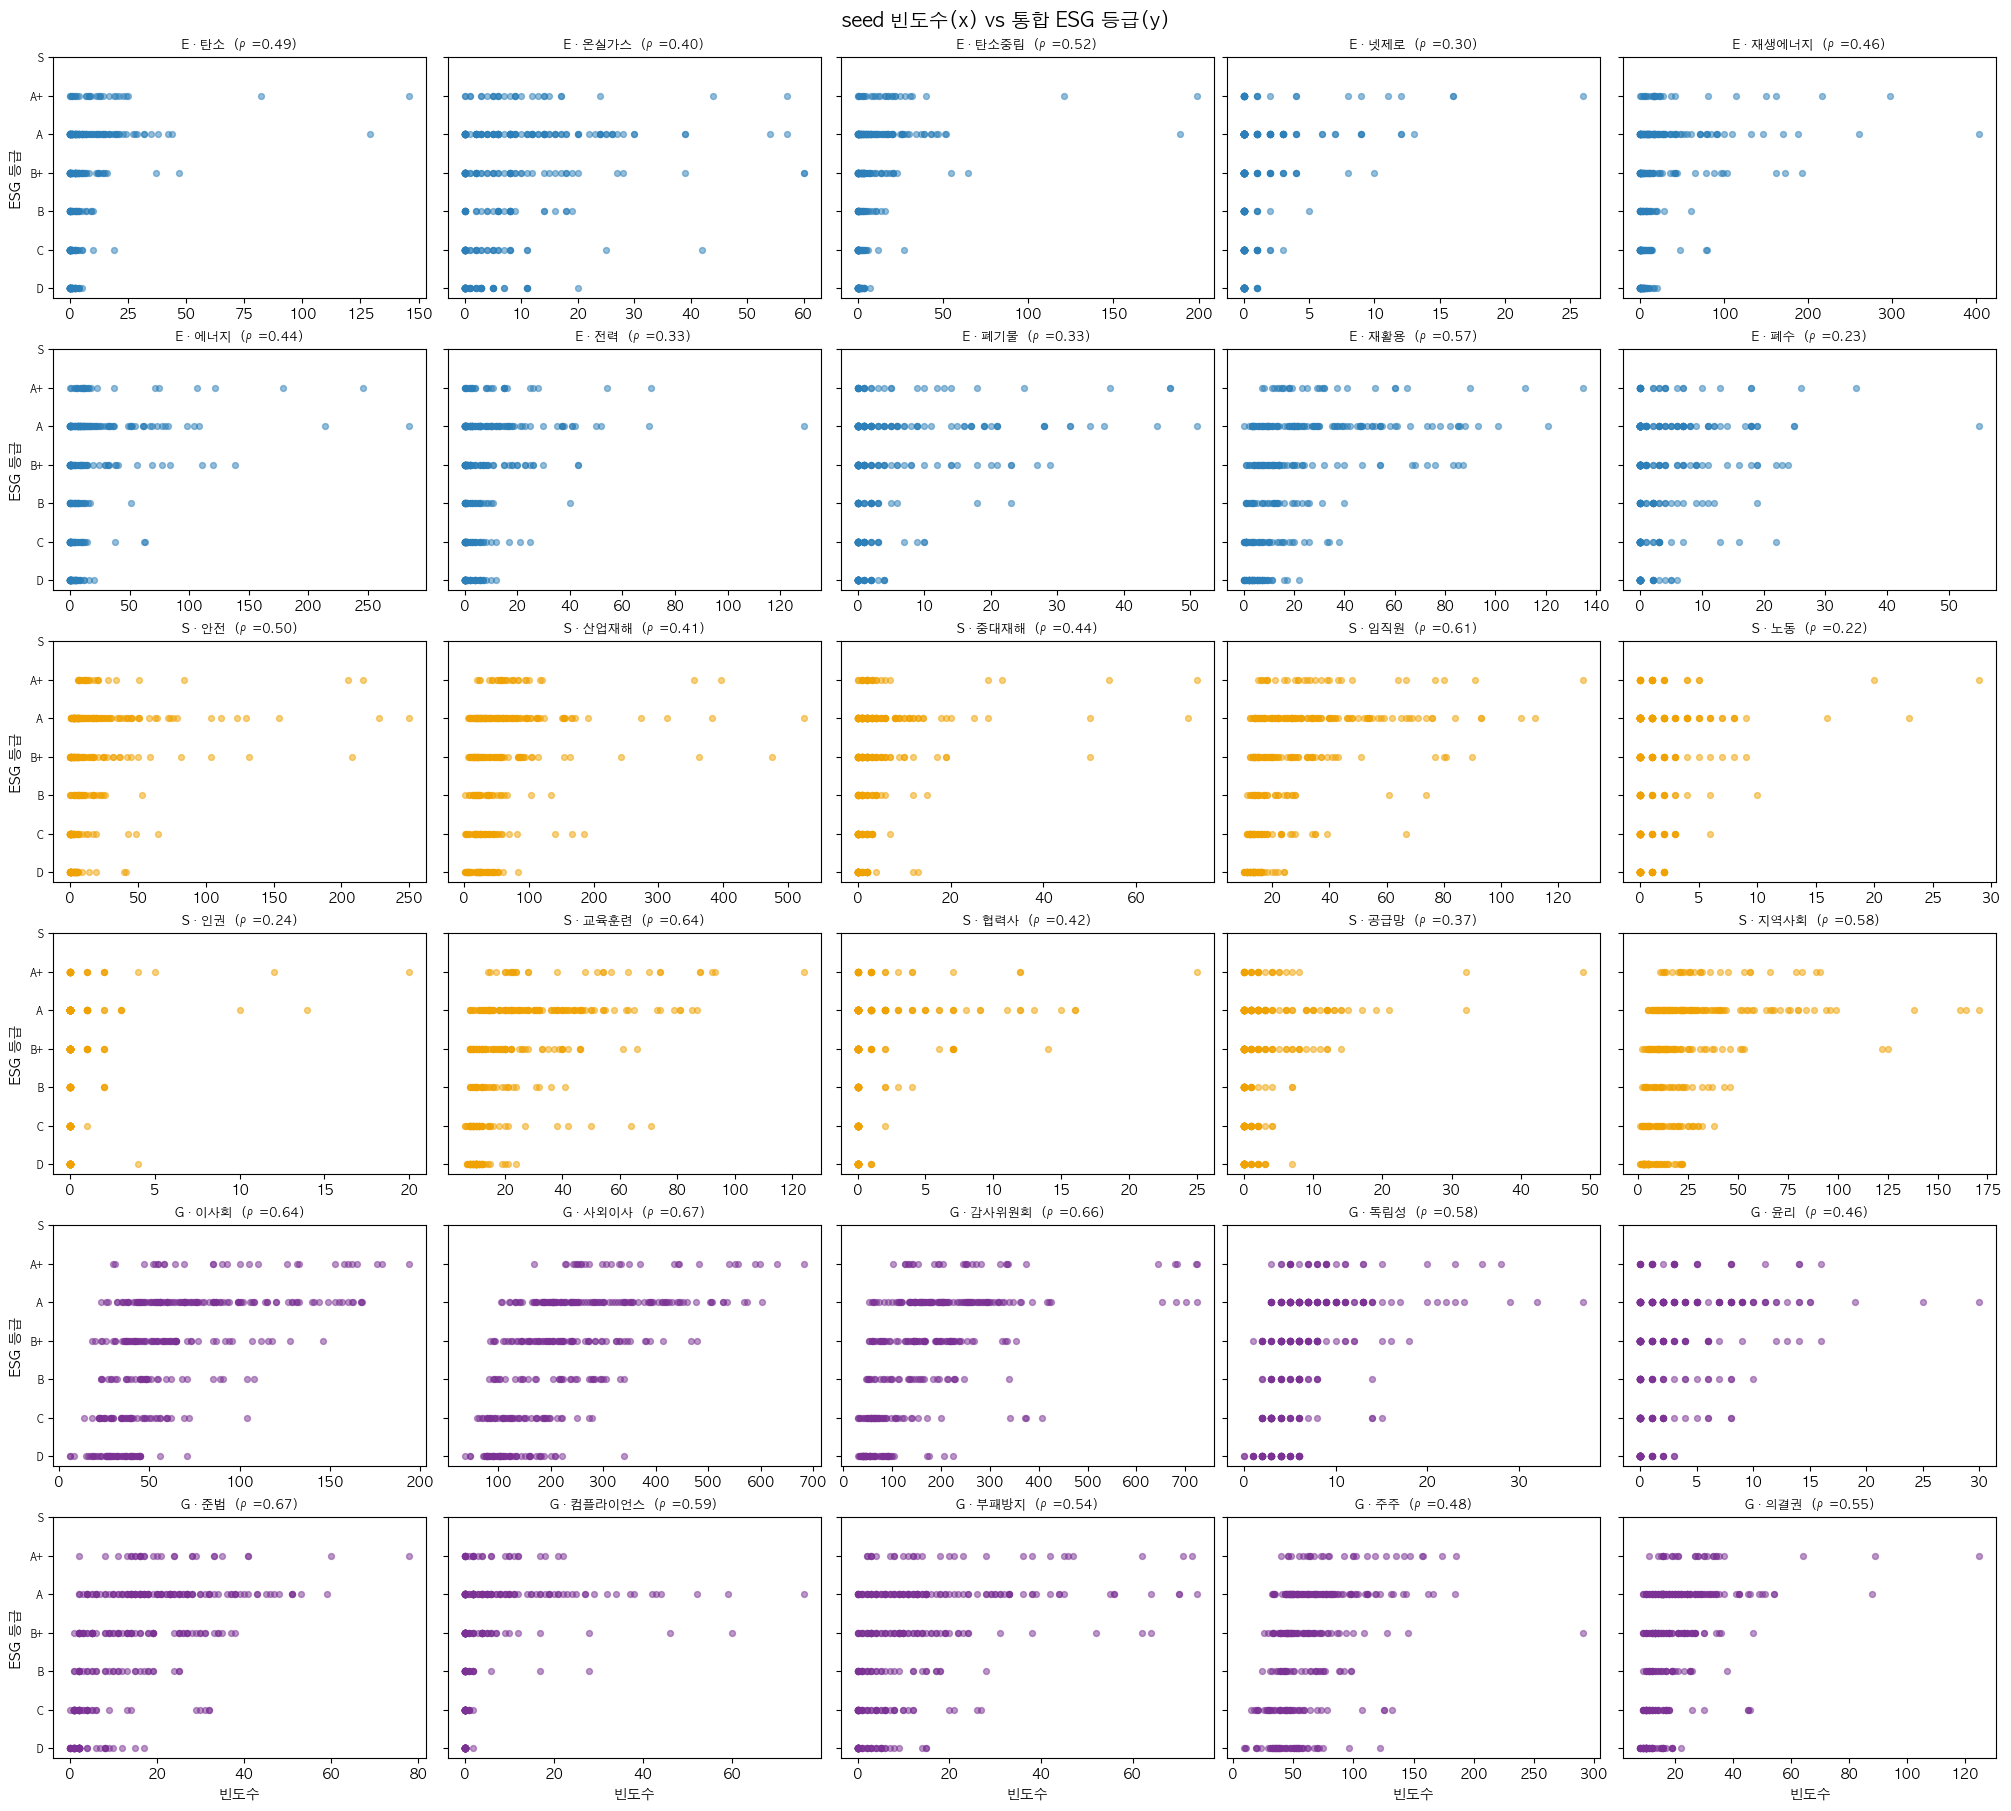

In [4]:
from sklearn.feature_extraction.text import CountVectorizer

# --- seed 사전 토크나이즈 (컷 없음) ---
sc_seed_dict = pd.read_csv(SEED_DICTIONARY_CSV)

with STOPWORDS_PATH.open('r', encoding='utf-8') as f:
    _sc_stop = {
        unicodedata.normalize('NFKC', line.strip()).lower()
        for line in f
        if line.strip() and not line.strip().startswith('#')
    }
_sc_stop |= {'i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x', 'xi', 'xii'}

sc_kiwi = Kiwi()
_SC_RE = re.compile(r'^[가-힣A-Za-z]+$')


def _sc_norm(word):
    return unicodedata.normalize('NFKC', str(word)).lower().strip()


def _sc_tokenize(phrase):
    if not isinstance(phrase, str) or not phrase.strip():
        return []
    phrase = _sc_norm(phrase)
    out = set()
    compact = re.sub(r'[^가-힣A-Za-z]+', '', phrase)
    if len(compact) > 1 and _SC_RE.fullmatch(compact):
        out.add(compact)
    for part in re.split(r'[^가-힣A-Za-z]+', phrase):
        if len(part) > 1 and _SC_RE.fullmatch(part):
            out.add(part)
    for token in sc_kiwi.tokenize(phrase):
        w = _sc_norm(token.form)
        if len(w) > 1 and _SC_RE.fullmatch(w) and (token.tag.startswith(('N', 'V')) or token.tag == 'SL'):
            out.add(w)
    return sorted(out)


def _sc_candidate(row):
    phrases = [row['seed_term']]
    if isinstance(row.get('pattern'), str):
        phrases.extend(row['pattern'].split('|'))
    terms = []
    for p in phrases:
        terms.extend(_sc_tokenize(p))
    return sorted({t for t in terms if t not in _sc_stop})


sc_seed_dict['candidate_terms'] = sc_seed_dict.apply(_sc_candidate, axis=1)

# --- seed 단어 원시 빈도수 (min_df/max_df 컷 없이 seed 단어만 count) ---
sc_all_terms = sorted({t for terms in sc_seed_dict['candidate_terms'] for t in terms})
sc_vectorizer = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, vocabulary=sc_all_terms)
sc_counts = sc_vectorizer.fit_transform(corpus_df['kiwi_text'].tolist())
sc_term_idx = {t: i for i, t in enumerate(sc_vectorizer.get_feature_names_out())}


def sc_seed_freq(terms):
    cols = [sc_term_idx[t] for t in terms if t in sc_term_idx]
    if not cols:
        return np.zeros(sc_counts.shape[0], dtype=float)
    return np.asarray(sc_counts[:, cols].sum(axis=1)).ravel()


# y축: 통합 ESG 등급 (숫자 서열)
sc_y = corpus_df['esg_grade'].map(GRADE_MAP).to_numpy()
_sc_inv_grade = {v: k for k, v in GRADE_MAP.items()}
_sc_color = {'E': '#2C7FB8', 'S': '#F0A202', 'G': '#7B3294'}

# --- 산점도 30개 (5열 x 6행) ---
n_seed = len(sc_seed_dict)
ncols = 5
nrows = int(np.ceil(n_seed / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), constrained_layout=True)
axes = axes.ravel()
for idx, (ax, (_, row)) in enumerate(zip(axes, sc_seed_dict.iterrows())):
    x = sc_seed_freq(row['candidate_terms'])
    ax.scatter(x, sc_y, s=18, alpha=0.5, color=_sc_color[row['dimension']])
    rho = spearmanr(x, sc_y)[0] if len(np.unique(x)) > 1 else float('nan')
    ax.set_title(f"{row['dimension']} · {row['seed_term']}  (ρ={rho:.2f})", fontsize=9)
    ax.set_yticks(range(7))
    if idx % ncols == 0:
        ax.set_yticklabels([_sc_inv_grade[i] for i in range(7)], fontsize=7)
        ax.set_ylabel('ESG 등급')
    else:
        ax.set_yticklabels([])
    if idx >= n_seed - ncols:
        ax.set_xlabel('빈도수')
for ax in axes[n_seed:]:
    ax.axis('off')
fig.suptitle('seed 빈도수(x) vs 통합 ESG 등급(y)', fontsize=14)
plt.show()

## 4. TF-IDF 벡터 학습

`kiwi_text`는 이미 공백 구분 토큰 문자열이므로 `tokenizer=str.split`을 사용한다. `norm='l2'`를 고정해 문서 길이의 기계적 효과를 줄인다.


In [5]:
corpus_texts = corpus_df['kiwi_text'].tolist()

vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    preprocessor=None,
    lowercase=False,
    norm=TFIDF_NORM,
    sublinear_tf=False,
    min_df=TFIDF_MIN_DF,
    max_df=TFIDF_MAX_DF,
)

X = vectorizer.fit_transform(corpus_texts)
vocab = vectorizer.get_feature_names_out()
vocab_to_idx = {term: idx for idx, term in enumerate(vocab)}

density = X.nnz / (X.shape[0] * X.shape[1])
print('TF-IDF matrix shape:', X.shape)
print('vocab size:', len(vocab))
print(f'density: {density:.6f}')
print('샘플 vocab:', vocab[:20])


TF-IDF matrix shape: (381, 40101)
vocab size: 40101
density: 0.043027
샘플 vocab: ['aa' 'aaa' 'aaai' 'aac' 'aachen' 'aacr' 'aaf' 'aaji' 'aak' 'aalto' 'aam'
 'aap' 'aaps' 'aasld' 'ab' 'abadi' 'abang' 'abb' 'abbott' 'abbvie']


## 5. L2 정규화 검증

각 문서 벡터의 L2 norm이 1인지 확인한다. 모든 문서에 TF-IDF vocabulary에 남은 토큰이 있어야 이 검증이 통과한다.


In [6]:
row_norms = np.sqrt(X.power(2).sum(axis=1)).A1
bad_norm_mask = ~np.isclose(row_norms, 1.0)

print(pd.Series(row_norms).describe().to_string())
if bad_norm_mask.any():
    display(corpus_df.loc[bad_norm_mask, ['company_name', 'stock_code', 'fiscal_year', 'esg_year']].head())

assert np.allclose(row_norms, 1.0), 'L2 정규화 sanity check 실패: 일부 문서 벡터 norm이 1이 아닙니다.'
print('L2 정규화 검증 통과:', np.allclose(row_norms, 1.0))


count    3.810000e+02
mean     1.000000e+00
std      2.549381e-15
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
L2 정규화 검증 통과: True


## 6. Seed dictionary 로드 및 TF-IDF vocab 매칭

`seed_term`과 `pattern`을 모두 사용한다. 각 phrase는 정규화, compact term 생성, 구분자 분해, Kiwi 토큰화를 거쳐 TF-IDF vocabulary와 맞춘다.


In [7]:
seed_dictionary = pd.read_csv(SEED_DICTIONARY_CSV)
assert {'dimension', 'seed_term', 'pattern'} <= set(seed_dictionary.columns), 'seed_dictionary 필수 컬럼 누락'
assert len(seed_dictionary) == 30, f'seed_dictionary는 30행이어야 합니다. 현재: {len(seed_dictionary)}'
assert seed_dictionary.groupby('dimension').size().to_dict() == {'E': 10, 'G': 10, 'S': 10}, (
    'seed_dictionary는 E/S/G 각 10개여야 합니다.'
)

with STOPWORDS_PATH.open('r', encoding='utf-8') as f:
    stopwords = {
        unicodedata.normalize('NFKC', line.strip()).lower()
        for line in f
        if line.strip() and not line.strip().startswith('#')
    }
stopwords |= {'i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x', 'xi', 'xii'}

kiwi = Kiwi()
KEEP_POS_PREFIXES = ('N', 'V')
KEEP_POS_TAGS = {'SL'}
TOKEN_RE = re.compile(r'^[가-힣A-Za-z]+$')


def normalize_word(word: object) -> str:
    return unicodedata.normalize('NFKC', str(word)).lower().strip()


def tokenize_seed_phrase(phrase: object) -> list[str]:
    if not isinstance(phrase, str) or not phrase.strip():
        return []

    phrase = normalize_word(phrase)
    out: set[str] = set()

    compact = re.sub(r'[^가-힣A-Za-z]+', '', phrase)
    if len(compact) > 1 and TOKEN_RE.fullmatch(compact):
        out.add(compact)

    for part in re.split(r'[^가-힣A-Za-z]+', phrase):
        if len(part) > 1 and TOKEN_RE.fullmatch(part):
            out.add(part)

    for token in kiwi.tokenize(phrase):
        word = normalize_word(token.form)
        if len(word) <= 1 or not TOKEN_RE.fullmatch(word):
            continue
        if not (token.tag.startswith(KEEP_POS_PREFIXES) or token.tag in KEEP_POS_TAGS):
            continue
        out.add(word)

    return sorted(out)


def seed_candidate_terms(row: pd.Series) -> list[str]:
    phrases = [row['seed_term']]
    if isinstance(row.get('pattern'), str):
        phrases.extend(row['pattern'].split('|'))

    terms: list[str] = []
    for phrase in phrases:
        terms.extend(tokenize_seed_phrase(phrase))

    return sorted({term for term in terms if term not in stopwords})


seed_dictionary['candidate_terms'] = seed_dictionary.apply(seed_candidate_terms, axis=1)
seed_dictionary['found_terms'] = seed_dictionary['candidate_terms'].map(
    lambda terms: [term for term in terms if term in vocab_to_idx]
)
seed_dictionary['missing_terms'] = seed_dictionary['candidate_terms'].map(
    lambda terms: [term for term in terms if term not in vocab_to_idx]
)
seed_dictionary['matched_vocab_count'] = seed_dictionary['found_terms'].map(len)

seed_match_report = seed_dictionary[
    ['dimension', 'seed_term', 'pattern', 'candidate_terms', 'found_terms', 'missing_terms', 'matched_vocab_count']
].copy()

found_by_dim = {
    dim: sorted({term for terms in seed_dictionary.loc[seed_dictionary['dimension'] == dim, 'found_terms'] for term in terms})
    for dim in ESG_DIMS
}
missing_by_dim = {
    dim: sorted({term for terms in seed_dictionary.loc[seed_dictionary['dimension'] == dim, 'missing_terms'] for term in terms})
    for dim in ESG_DIMS
}

print('dimension별 vocab 매칭 term 수:', {dim: len(terms) for dim, terms in found_by_dim.items()})
print('dimension별 missing term:', missing_by_dim)

missing_seed_rows = seed_match_report[seed_match_report['matched_vocab_count'] == 0]
if not missing_seed_rows.empty:
    print('경고: vocab에 매칭되는 term이 하나도 없는 seed가 있습니다. 해당 seed는 0점 처리됩니다.')
    display(missing_seed_rows)

display(seed_match_report)


dimension별 vocab 매칭 term 수: {'E': 20, 'S': 14, 'G': 11}
dimension별 missing term: {'E': ['ghg', 'renewableenergy', '물관리', '자원순환', '재생에너지', '전력사용량', '탄소중립'], 'S': ['supplychain', '교육', '교육훈련', '근로자', '사회', '산업', '산업재해', '재해율', '중대재해', '지역사회', '직원'], 'G': ['anticorruption', 'corruption', 'ethic', 'independence', 'voting', 'votingrights', '감사', '독립', '독립성', '반부패', '부패방지', '사외', '사외이사', '사회', '위원회', '의결', '이사', '이사회', '주주', '준법', '컴플라이언스']}
경고: vocab에 매칭되는 term이 하나도 없는 seed가 있습니다. 해당 seed는 0점 처리됩니다.


,dimension,seed_term,pattern,candidate_terms,found_terms,missing_terms,matched_vocab_count
20,G,이사회,이사회,"[사회, 이사회]",[],"[사회, 이사회]",0
21,G,사외이사,사외이사,"[사외, 사외이사, 이사]",[],"[사외, 사외이사, 이사]",0
23,G,독립성,독립성|independence,"[independence, 독립, 독립성]",[],"[independence, 독립, 독립성]",0
28,G,주주,주주,[주주],[],[주주],0


,dimension,seed_term,pattern,candidate_terms,found_terms,missing_terms,matched_vocab_count
0,E,탄소,탄소,[탄소],[탄소],[],1
1,E,온실가스,온실가스|GHG,"[ghg, 온실가스]",[온실가스],[ghg],1
2,E,탄소중립,탄소중립,"[중립, 탄소, 탄소중립]","[중립, 탄소]",[탄소중립],2
3,E,넷제로,넷제로|net zero|net-zero,"[net, netzero, zero, 넷제로]","[net, netzero, zero, 넷제로]",[],4
4,E,재생에너지,재생에너지|renewable energy,"[energy, renewable, renewableenergy, 에너지, 재생, ...","[energy, renewable, 에너지, 재생]","[renewableenergy, 재생에너지]",4
5,E,에너지,에너지,[에너지],[에너지],[],1
6,E,전력,전력|전력사용량,"[사용량, 전력, 전력사용량]","[사용량, 전력]",[전력사용량],2
7,E,폐기물,폐기물,[폐기물],[폐기물],[],1
8,E,재활용,재활용|자원순환,"[순환, 자원, 자원순환, 재활용, 활용]","[순환, 자원, 재활용, 활용]",[자원순환],4
9,E,폐수,폐수|수질|물관리,"[물관리, 수질, 폐수]","[수질, 폐수]",[물관리],2


## 7. Dimension별 seed TF-IDF 합산

같은 dimension 안에서 여러 seed가 같은 vocabulary term에 매칭될 수 있으므로, dimension별로 고유 term을 만든 뒤 한 번만 합산한다.


In [8]:
def sum_seed_columns(X_sparse, vocab_index: dict[str, int], seed_words: list[str]) -> np.ndarray:
    col_indices = [vocab_index[word] for word in sorted(set(seed_words)) if word in vocab_index]
    if not col_indices:
        return np.zeros(X_sparse.shape[0], dtype=float)
    return np.asarray(X_sparse[:, col_indices].sum(axis=1)).ravel()


tfidf_scores = {
    dim: sum_seed_columns(X, vocab_to_idx, found_by_dim[dim])
    for dim in ESG_DIMS
}

for dim in ESG_DIMS:
    print(f'{dim}: matched terms={len(found_by_dim[dim])}, score mean={tfidf_scores[dim].mean():.6f}, max={tfidf_scores[dim].max():.6f}')


E: matched terms=20, score mean=0.096426, max=0.495481
S: matched terms=14, score mean=0.054287, max=0.269324
G: matched terms=11, score mean=0.028135, max=0.218621


## 8. 피처 테이블 조립 및 분포 확인

최종 피처는 `company_name`, `stock_code`, `fiscal_year`, `esg_year`와 `tfidf_E/S/G`만 포함한다. 저장 전 PK 유일성을 다시 확인한다.


,company_name,stock_code,fiscal_year,esg_year,tfidf_E,tfidf_S,tfidf_G
0,동화약품,000020,2022,2023,0.054691,0.063102,0.060448
1,동화약품,000020,2023,2024,0.050116,0.051056,0.036249
2,동화약품,000020,2024,2025,0.062979,0.053052,0.029883
3,KR모터스,000040,2022,2023,0.019509,0.023280,0.000000
4,KR모터스,000040,2023,2024,0.008182,0.029795,0.000000


,tfidf_E,tfidf_S,tfidf_G
count,381.000000,381.000000,381.000000
mean,0.096426,0.054287,0.028135
std,0.094074,0.038622,0.028719
min,0.000000,0.000000,0.000000
25%,0.025284,0.028036,0.009117
50%,0.059697,0.044996,0.021289
75%,0.143199,0.069082,0.036108
max,0.495481,0.269324,0.218621


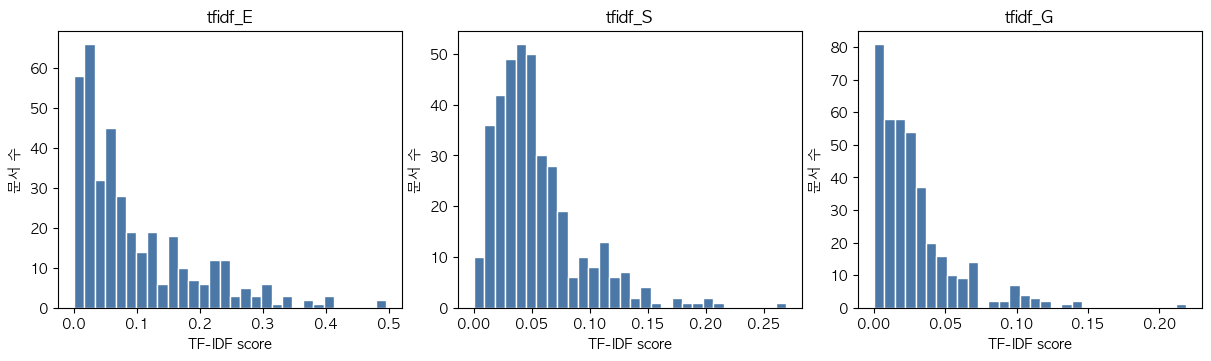

In [9]:
features = pd.DataFrame({
    'company_name': corpus_df['company_name'],
    'stock_code': corpus_df['stock_code'],
    'fiscal_year': corpus_df['fiscal_year'],
    'esg_year': corpus_df['esg_year'],
    'tfidf_E': tfidf_scores['E'],
    'tfidf_S': tfidf_scores['S'],
    'tfidf_G': tfidf_scores['G'],
})

assert len(features) == len(corpus_df), 'features 행 수가 corpus_df와 다릅니다.'
assert features[STRICT_KEY_COLS].notna().all().all(), 'features 키 컬럼에 결측이 있습니다.'
assert features.duplicated(KEY_COLS).sum() == 0, 'features의 stock_code + fiscal_year 중복이 있습니다.'
assert features[TEXT_COLS].notna().all().all(), 'TF-IDF 피처에 결측이 있습니다.'

display(features.head())
display(features[TEXT_COLS].describe())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, col in zip(axes, TEXT_COLS):
    ax.hist(features[col], bins=30, color='#4C78A8', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('TF-IDF score')
    ax.set_ylabel('문서 수')
plt.show()


## 9. ESG 등급 데이터 준비 및 merge

등급 데이터는 `company_master.csv`에서 가져온다. merge는 `stock_code + fiscal_year + esg_year` 기준으로 검증하며, 등급 문자는 숫자 서열로 변환한다.


In [10]:
grades = master[
    ['company_name', 'stock_code', 'fiscal_year', 'esg_year', 'esg_grade', 'e_grade', 's_grade', 'g_grade']
].copy()
grades = grades.sort_values(KEY_COLS).reset_index(drop=True)

for col in ['esg_grade', 'e_grade', 's_grade', 'g_grade']:
    grades[col] = grades[col].astype(str).str.strip()

grades['esg_grade_num'] = grades['esg_grade'].map(GRADE_MAP)
grades['e_grade_num'] = grades['e_grade'].map(GRADE_MAP)
grades['s_grade_num'] = grades['s_grade'].map(GRADE_MAP)
grades['g_grade_num'] = grades['g_grade'].map(GRADE_MAP)
grades['high_esg'] = (grades['esg_grade_num'] >= HIGH_ESG_CUTOFF).astype(int)

assert grades.duplicated(STRICT_KEY_COLS).sum() == 0, 'grades의 strict key 중복이 있습니다.'
assert grades['esg_grade_num'].notna().all(), '숫자화되지 않은 통합 ESG 등급이 있습니다.'
assert grades[GRADE_NUM_COLS].notna().all().all(), '숫자화되지 않은 E/S/G 등급이 있습니다.'
assert set(grades['high_esg'].dropna().unique()) == {0, 1}, 'high_esg가 0/1 두 클래스를 모두 가져야 합니다.'

merged = features.merge(
    grades[STRICT_KEY_COLS + ['esg_grade', 'e_grade', 's_grade', 'g_grade', 'esg_grade_num', 'high_esg'] + GRADE_NUM_COLS],
    on=STRICT_KEY_COLS,
    how='left',
    validate='one_to_one',
    indicator=True,
)

match_rate = (merged['_merge'] == 'both').mean()
grade_attached_rate = merged[[INTEGRATED_GRADE_NUM_COL] + GRADE_NUM_COLS].notna().all(axis=1).mean()
assert match_rate == 1.0, '등급 merge 누락 행이 있습니다.'
assert grade_attached_rate == 1.0, '통합 ESG 및 E/S/G 숫자 등급이 붙지 않은 행이 있습니다.'
assert set(merged['high_esg'].dropna().unique()) == {0, 1}, 'merged high_esg가 0/1 두 클래스를 모두 가져야 합니다.'
merged = merged.drop(columns=['_merge'])

print(f'등급 매칭률: {match_rate:.1%} ({int(match_rate * len(features))}/{len(features)})')
print(f'통합 ESG 및 E/S/G 등급 부착률: {grade_attached_rate:.1%}')
print('high_esg 분포 (A 이상=1):')
print(merged['high_esg'].value_counts().sort_index().to_string())
display(merged[['company_name', 'stock_code', 'fiscal_year', 'esg_year'] + TEXT_COLS + ['esg_grade_num', 'high_esg'] + GRADE_NUM_COLS].head())
display(merged[['esg_grade', 'e_grade', 's_grade', 'g_grade']].apply(pd.Series.value_counts).fillna(0).astype(int))


등급 매칭률: 100.0% (381/381)
통합 ESG 및 E/S/G 등급 부착률: 100.0%
high_esg 분포 (A 이상=1):
high_esg
0    229
1    152


,company_name,stock_code,fiscal_year,esg_year,tfidf_E,tfidf_S,tfidf_G,esg_grade_num,high_esg,e_grade_num,s_grade_num,g_grade_num
0,동화약품,000020,2022,2023,0.054691,0.063102,0.060448,1,0,1,2,1
1,동화약품,000020,2023,2024,0.050116,0.051056,0.036249,1,0,2,2,1
2,동화약품,000020,2024,2025,0.062979,0.053052,0.029883,1,0,2,1,1
3,KR모터스,000040,2022,2023,0.019509,0.023280,0.000000,0,0,0,0,0
4,KR모터스,000040,2023,2024,0.008182,0.029795,0.000000,0,0,0,0,0


,esg_grade,e_grade,s_grade,g_grade
A,123,130,97,85
A+,29,42,136,18
B,36,29,14,48
B+,76,74,33,99
C,53,64,34,68
D,64,42,67,63


## 10. 3x3 Spearman 교차표 계산

`tfidf_E/S/G`와 `e/s/g_grade_num`의 모든 조합에 대해 Spearman 순위상관계수와 p-value를 계산한다.


In [11]:
rho_matrix = pd.DataFrame(index=TEXT_COLS, columns=GRADE_NUM_COLS, dtype=float)
pval_matrix = pd.DataFrame(index=TEXT_COLS, columns=GRADE_NUM_COLS, dtype=float)

spearman_data = merged.dropna(subset=TEXT_COLS + GRADE_NUM_COLS).copy()
assert len(spearman_data) > 0, 'Spearman 계산 가능한 데이터가 없습니다.'

for text_col in TEXT_COLS:
    for grade_col in GRADE_NUM_COLS:
        pair = spearman_data[[text_col, grade_col]].dropna()
        if pair[text_col].nunique() < 2 or pair[grade_col].nunique() < 2:
            rho, pval = np.nan, np.nan
        else:
            rho, pval = spearmanr(pair[text_col], pair[grade_col])
        rho_matrix.loc[text_col, grade_col] = rho
        pval_matrix.loc[text_col, grade_col] = pval

print('Spearman rho matrix')
display(rho_matrix)
print('p-value matrix')
display(pval_matrix)


Spearman rho matrix


,e_grade_num,s_grade_num,g_grade_num
tfidf_E,0.358826,0.305958,0.202571
tfidf_S,0.358355,0.384942,0.352835
tfidf_G,0.421906,0.469726,0.509938


p-value matrix


,e_grade_num,s_grade_num,g_grade_num
tfidf_E,5.087856e-13,1.065292e-09,6.822370e-05
tfidf_S,5.482305e-13,6.630152e-15,1.304076e-12
tfidf_G,7.074887e-18,2.634476e-22,1.309064e-26


## 11. Spearman 교차표 heatmap

색은 rho 값을 나타내며, 각 셀 annotation에는 rho와 유의수준 별표를 함께 표기한다.


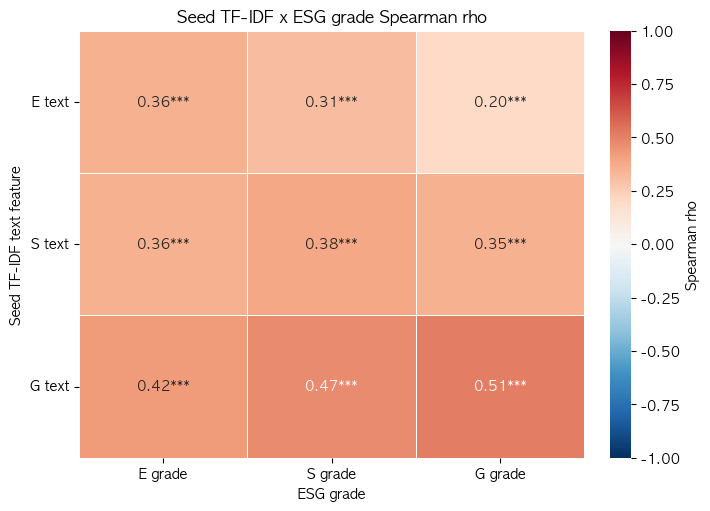

heatmap 저장: /Users/home1/esg-dart-project/reports/figures/05_tfidf_seed_spearman_heatmap.png


In [12]:
def pvalue_stars(pval: float) -> str:
    if pd.isna(pval):
        return ''
    if pval < 0.001:
        return '***'
    if pval < 0.01:
        return '**'
    if pval < 0.05:
        return '*'
    return ''


annot = rho_matrix.copy().astype(object)
for row in rho_matrix.index:
    for col in rho_matrix.columns:
        rho = rho_matrix.loc[row, col]
        pval = pval_matrix.loc[row, col]
        annot.loc[row, col] = 'NA' if pd.isna(rho) else f'{rho:.2f}{pvalue_stars(pval)}'

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
sns.heatmap(
    rho_matrix.astype(float),
    annot=annot,
    fmt='',
    center=0,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Spearman rho'},
    ax=ax,
)
ax.set_title('Seed TF-IDF x ESG grade Spearman rho')
ax.set_xlabel('ESG grade')
ax.set_ylabel('Seed TF-IDF text feature')
ax.set_xticklabels(['E grade', 'S grade', 'G grade'])
ax.set_yticklabels(['E text', 'S text', 'G text'], rotation=0)

fig.savefig(OUTPUT_HEATMAP, dpi=200, bbox_inches='tight')
plt.show()

print('heatmap 저장:', OUTPUT_HEATMAP)


## 12. 해석

- **대각선이 강하고 비대각선이 약함** -> 차원별 텍스트 측정이 성공한 패턴이다. 예를 들어 E 텍스트는 E 등급과, S 텍스트는 S 등급과, G 텍스트는 G 등급과 상대적으로 더 강하게 연결된다.
- **비대각선까지 강함** -> 공시량/문서량 효과를 의심해야 한다. E/S/G 모든 텍스트 점수가 함께 커지는 경우, 특정 차원의 실질 신호가 아니라 "ESG를 많이 쓴 회사" 효과일 수 있다.
- 이 경우 이후 단계에서 Dense cosine과 비교하고, 회귀 단계에서 공시분량 통제가 필수다.
- 아래 회귀 섹션은 통제변수 없는 baseline 검증이다. fastText 확장, Dense embedding, 자산/산업 통제 회귀는 수행하지 않는다.


Seed TF-IDF 점수는 E/S/G 등급 모두와 유의한 양의 Spearman 상관을 보였다. 특히 대각선 상관은 E 0.36, S 0.38, G 0.51로 나타나 seed 기반 텍스트 feature가 ESG 평가와 일정한 수렴타당도를 갖는 것으로 보인다. 다만 비대각선 상관도 전반적으로 높아, 각 차원이 독립적으로 분리되었다기보다는 ESG 공시 전반의 충실도 또는 기업의 전반적 ESG maturity를 함께 반영하는 것으로 해석된다.

## 13. 회귀 패널 구성

통합 ESG 등급(`esg_grade_num`)을 종속변수로 두고, `tfidf_E`, `tfidf_S`, `tfidf_G`를 함께 투입한다. Binary Logit은 A 이상(`esg_grade_num >= 4`)을 우수 그룹으로 정의한다.


In [13]:
regression_panel = merged.dropna(
    subset=[INTEGRATED_GRADE_NUM_COL, 'high_esg'] + REGRESSION_FEATURES
).copy()

assert len(regression_panel) > 0, '회귀에 사용할 행이 없습니다.'
assert regression_panel[INTEGRATED_GRADE_NUM_COL].notna().all(), 'esg_grade_num 결측이 있습니다.'
assert regression_panel['high_esg'].notna().all(), 'high_esg 결측이 있습니다.'
assert set(regression_panel['high_esg'].unique()) == {0, 1}, 'Binary Logit을 위해 high_esg는 0/1 두 클래스를 모두 가져야 합니다.'
assert regression_panel[REGRESSION_FEATURES].notna().all().all(), '회귀 설명변수에 결측이 있습니다.'

print('회귀 패널 shape:', regression_panel.shape)
print('통합 ESG 등급 분포:')
print(regression_panel['esg_grade'].value_counts().sort_index().to_string())
print('\nhigh_esg 분포 (A 이상=1):')
print(regression_panel['high_esg'].value_counts().sort_index().to_string())
display(regression_panel[['company_name', 'stock_code', 'fiscal_year', 'esg_grade', 'esg_grade_num', 'high_esg'] + REGRESSION_FEATURES].head())


회귀 패널 shape: (381, 16)
통합 ESG 등급 분포:
esg_grade
A     123
A+     29
B      36
B+     76
C      53
D      64

high_esg 분포 (A 이상=1):
high_esg
0    229
1    152


,company_name,stock_code,fiscal_year,esg_grade,esg_grade_num,high_esg,tfidf_E,tfidf_S,tfidf_G
0,동화약품,000020,2022,C,1,0,0.054691,0.063102,0.060448
1,동화약품,000020,2023,C,1,0,0.050116,0.051056,0.036249
2,동화약품,000020,2024,C,1,0,0.062979,0.053052,0.029883
3,KR모터스,000040,2022,D,0,0,0.019509,0.023280,0.000000
4,KR모터스,000040,2023,D,0,0,0.008182,0.029795,0.000000


## 14. OLS 회귀분석

OLS는 통합 ESG 등급을 연속형 점수처럼 본 baseline이다. `HC3` robust standard error를 사용한다.


In [14]:
ols_X = sm.add_constant(regression_panel[REGRESSION_FEATURES], has_constant='add')
ols_y = regression_panel[INTEGRATED_GRADE_NUM_COL]

ols_result = sm.OLS(ols_y, ols_X).fit(cov_type='HC3')
print(ols_result.summary())

ols_coef_table = pd.DataFrame({
    'term': ols_result.params.index,
    'coef': ols_result.params.values,
    'std_err': ols_result.bse.values,
    'p_value': ols_result.pvalues.values,
})
ols_coef_table['model'] = 'OLS'
ols_coef_table['metric_name'] = 'r_squared'
ols_coef_table['metric_value'] = ols_result.rsquared
display(ols_coef_table)


                            OLS Regression Results                            
Dep. Variable:          esg_grade_num   R-squared:                       0.243
Model:                            OLS   Adj. R-squared:                  0.237
Method:                 Least Squares   F-statistic:                     42.41
Date:                Wed, 03 Jun 2026   Prob (F-statistic):           1.23e-23
Time:                        13:23:00   Log-Likelihood:                -671.74
No. Observations:                 381   AIC:                             1351.
Df Residuals:                     377   BIC:                             1367.
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.4417      0.138     10.430      0.0

,term,coef,std_err,p_value,model,metric_name,metric_value
0,const,1.441686,0.138228,1.813192e-25,OLS,r_squared,0.242836
1,tfidf_E,2.415290,0.782833,2.033341e-03,OLS,r_squared,0.242836
2,tfidf_S,6.892962,1.958728,4.330125e-04,OLS,r_squared,0.242836
3,tfidf_G,19.535968,2.816558,4.030334e-12,OLS,r_squared,0.242836


통제변수 없이 텍스트 seed 3개만으로 통합 ESG 등급 변동의 약 24%를 설명

## 15. Binary Logit 회귀분석

Binary Logit은 A 이상 여부(`high_esg`)를 종속변수로 둔다. 계수와 함께 odds ratio를 출력한다.


In [15]:
binary_X = sm.add_constant(regression_panel[REGRESSION_FEATURES], has_constant='add')
binary_y = regression_panel['high_esg']

binary_logit_result = sm.Logit(binary_y, binary_X).fit(disp=False)
print(binary_logit_result.summary())

binary_coef_table = pd.DataFrame({
    'term': binary_logit_result.params.index,
    'coef': binary_logit_result.params.values,
    'std_err': binary_logit_result.bse.values,
    'p_value': binary_logit_result.pvalues.values,
})
binary_coef_table['odds_ratio'] = np.exp(binary_coef_table['coef'])
binary_coef_table['model'] = 'Binary Logit'
binary_coef_table['metric_name'] = 'pseudo_r_squared'
binary_coef_table['metric_value'] = binary_logit_result.prsquared
display(binary_coef_table)


                           Logit Regression Results                           
Dep. Variable:               high_esg   No. Observations:                  381
Model:                          Logit   Df Residuals:                      377
Method:                           MLE   Df Model:                            3
Date:                Wed, 03 Jun 2026   Pseudo R-squ.:                  0.1593
Time:                        13:23:00   Log-Likelihood:                -215.43
converged:                       True   LL-Null:                       -256.25
Covariance Type:            nonrobust   LLR p-value:                 1.355e-17
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.9309      0.243     -7.961      0.000      -2.406      -1.456
tfidf_E        2.6271      1.368      1.920      0.055      -0.054       5.308
tfidf_S        5.9343      3.363      1.765      0.0

,term,coef,std_err,p_value,odds_ratio,model,metric_name,metric_value
0,const,-1.930865,0.242532,1.702744e-15,1.450227e-01,Binary Logit,pseudo_r_squared,0.159324
1,tfidf_E,2.627067,1.368006,5.481215e-02,1.383314e+01,Binary Logit,pseudo_r_squared,0.159324
2,tfidf_S,5.934338,3.362563,7.759307e-02,3.777900e+02,Binary Logit,pseudo_r_squared,0.159324
3,tfidf_G,33.382177,5.655095,3.568922e-09,3.145539e+14,Binary Logit,pseudo_r_squared,0.159324


A 이상 우수 등급 여부를 설명할 때는 tfidf_G만 뚜렷하게 유의

## 16. Ordered Logit 회귀분석

Ordered Logit은 ESG 등급의 서열성을 보존한다. `OrderedModel`에는 상수항을 넣지 않는다.


In [16]:
ordered_X = regression_panel[REGRESSION_FEATURES]
ordered_y = regression_panel[INTEGRATED_GRADE_NUM_COL]

ordered_model = OrderedModel(ordered_y, ordered_X, distr='logit')
ordered_logit_result = ordered_model.fit(method='bfgs', disp=False)
print(ordered_logit_result.summary())

ordered_coef_table = pd.DataFrame({
    'term': ordered_logit_result.params.index,
    'coef': ordered_logit_result.params.values,
    'std_err': ordered_logit_result.bse.values,
    'p_value': ordered_logit_result.pvalues.values,
})
ordered_coef_table = ordered_coef_table[ordered_coef_table['term'].isin(REGRESSION_FEATURES)].copy()
ordered_coef_table['model'] = 'Ordered Logit'
ordered_coef_table['metric_name'] = 'aic'
ordered_coef_table['metric_value'] = ordered_logit_result.aic
display(ordered_coef_table)


                             OrderedModel Results                             
Dep. Variable:          esg_grade_num   Log-Likelihood:                -590.04
Model:                   OrderedModel   AIC:                             1196.
Method:            Maximum Likelihood   BIC:                             1228.
Date:                Wed, 03 Jun 2026                                         
Time:                        13:23:00                                         
No. Observations:                 381                                         
Df Residuals:                     373                                         
Df Model:                           3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
tfidf_E        3.0691      1.072      2.863      0.004       0.968       5.170
tfidf_S        8.9100      2.715      3.282      0.0

,term,coef,std_err,p_value,model,metric_name,metric_value
0,tfidf_E,3.069098,1.071958,4.195476e-03,Ordered Logit,aic,1196.086201
1,tfidf_S,8.910034,2.714638,1.029939e-03,Ordered Logit,aic,1196.086201
2,tfidf_G,23.285877,3.628847,1.390949e-10,Ordered Logit,aic,1196.086201


- tfidf_E/S/G가 높을수록 통합 ESG 등급이 높은 경향이 있고, 그중 G 텍스트 점수의 설명력이 가장 강하게 나온다는 결과



세 회귀모형 모두에서 seed TF-IDF 변수는 통합 ESG 등급과 양의 관계를 보였다. OLS에서는 세 차원 모두 유의했으며, ordered logit에서도 E/S/G seed 점수가 높을수록 더 높은 ESG 등급에 속할 가능성이 유의하게 증가했다. Binary logit에서는 A 이상 우수등급 여부에 대해 G 텍스트 점수가 가장 강하고 안정적인 예측 신호를 보였다. 다만 본 모형은 통제변수 없는 baseline이므로, 결과는 인과효과가 아니라 텍스트 공시 강도와 ESG 등급 간의 연관성으로 해석해야 한다.

## 17. 회귀 결과 저장

세 모델의 핵심 계수표를 하나의 CSV로 저장하고, statsmodels 전체 summary는 모델별 텍스트 파일로 저장한다.


In [17]:
regression_summary = pd.concat(
    [ols_coef_table, binary_coef_table, ordered_coef_table],
    ignore_index=True,
    sort=False,
)
regression_summary = regression_summary[
    ['model', 'term', 'coef', 'std_err', 'p_value', 'odds_ratio', 'metric_name', 'metric_value']
]

regression_summary.to_csv(OUTPUT_REGRESSION_SUMMARY, index=False, encoding='utf-8-sig')
OUTPUT_OLS_SUMMARY.write_text(ols_result.summary().as_text(), encoding='utf-8')
OUTPUT_BINARY_LOGIT_SUMMARY.write_text(binary_logit_result.summary().as_text(), encoding='utf-8')
OUTPUT_ORDERED_LOGIT_SUMMARY.write_text(ordered_logit_result.summary().as_text(), encoding='utf-8')

for path in [OUTPUT_REGRESSION_SUMMARY, OUTPUT_OLS_SUMMARY, OUTPUT_BINARY_LOGIT_SUMMARY, OUTPUT_ORDERED_LOGIT_SUMMARY]:
    assert path.exists(), f'회귀 결과 저장 실패: {path}'
    print('회귀 결과 저장 완료:', path)

display(regression_summary)


회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_regression_summary.csv
회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_ols_summary.txt
회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_binary_logit_summary.txt
회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_ordered_logit_summary.txt


,model,term,coef,std_err,p_value,odds_ratio,metric_name,metric_value
0,OLS,const,1.441686,0.138228,1.813192e-25,NaN,r_squared,0.242836
1,OLS,tfidf_E,2.415290,0.782833,2.033341e-03,NaN,r_squared,0.242836
2,OLS,tfidf_S,6.892962,1.958728,4.330125e-04,NaN,r_squared,0.242836
3,OLS,tfidf_G,19.535968,2.816558,4.030334e-12,NaN,r_squared,0.242836
4,Binary Logit,const,-1.930865,0.242532,1.702744e-15,1.450227e-01,pseudo_r_squared,0.159324
5,Binary Logit,tfidf_E,2.627067,1.368006,5.481215e-02,1.383314e+01,pseudo_r_squared,0.159324
6,Binary Logit,tfidf_S,5.934338,3.362563,7.759307e-02,3.777900e+02,pseudo_r_squared,0.159324
7,Binary Logit,tfidf_G,33.382177,5.655095,3.568922e-09,3.145539e+14,pseudo_r_squared,0.159324
8,Ordered Logit,tfidf_E,3.069098,1.071958,4.195476e-03,NaN,aic,1196.086201
9,Ordered Logit,tfidf_S,8.910034,2.714638,1.029939e-03,NaN,aic,1196.086201


## 18. 산출물 저장

피처 테이블은 parquet로 저장하고, Spearman rho/p-value 교차표는 CSV로 저장한다. heatmap PNG는 앞 셀에서 저장했다.


In [18]:
features.to_parquet(OUTPUT_FEATURES, index=False)
rho_matrix.to_csv(OUTPUT_RHO, encoding='utf-8-sig')
pval_matrix.to_csv(OUTPUT_PVAL, encoding='utf-8-sig')

for path in [OUTPUT_FEATURES, OUTPUT_RHO, OUTPUT_PVAL, OUTPUT_HEATMAP]:
    assert path.exists(), f'저장 실패: {path}'
    print('저장 완료:', path)

print('\nfeatures shape:', features.shape)
display(features.head())


저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_features.parquet
저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_rho_matrix.csv
저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_pval_matrix.csv
저장 완료: /Users/home1/esg-dart-project/reports/figures/05_tfidf_seed_spearman_heatmap.png

features shape: (381, 7)


,company_name,stock_code,fiscal_year,esg_year,tfidf_E,tfidf_S,tfidf_G
0,동화약품,000020,2022,2023,0.054691,0.063102,0.060448
1,동화약품,000020,2023,2024,0.050116,0.051056,0.036249
2,동화약품,000020,2024,2025,0.062979,0.053052,0.029883
3,KR모터스,000040,2022,2023,0.019509,0.023280,0.000000
4,KR모터스,000040,2023,2024,0.008182,0.029795,0.000000


## 19. 결과 정리 — Seed TF-IDF (전체 흐름 4단계)

### 이 노트북의 위치

```
1 데이터수집 → 2 섹션구성(core II·IV·VI) → 3 동일 전처리
        │
        ├── 4 Seed TF-IDF (← 이 노트북)
        ├── 5 확장 TF-IDF (fastText θ 스윕·필터)      [별도 노트북]
        └── 6 Dense cosine (기준문장 임베딩)            [별도 노트북]
                                │
                7 회귀 OLS/logit : 통제 없 → 통제 추가(size·industry·공시분량)
                                │
                8 피처 비교·메인 렌즈 선택
                                │
                9 해석 : cheap-talk vs disclosure signal
```

이 노트북은 **4단계(Seed TF-IDF)만** 담당한다. 5·6은 같은 전처리 코퍼스를 입력으로 받는 별도 측정이고, 7~9는 세 피처를 한자리에 모은 뒤 진행한다. 즉 여기 회귀(14~16번 셀)는 seed 피처만 넣은 **baseline**이며, 본 회귀는 7단계에서 통제변수를 넣어 다시 돌린다.

### 무엇을 측정했나

- 입력: core(II·IV·VI) 본문 → Kiwi 토큰 → `TfidfVectorizer(min_df=2, max_df=0.95, norm='l2')`. 문서 단위 = 기업 × 회계연도, 총 381개.
- seed_dictionary 30개(E/S/G 각 10개)를 TF-IDF vocab에 매칭하고 차원별로 TF-IDF를 합산 → `tfidf_E / tfidf_S / tfidf_G`.
- 등급 매칭은 `esg_year = fiscal_year + 1`, 키는 `stock_code × fiscal_year` (회사명 merge 금지).
- **주의**: 이 점수는 ESG *성과*가 아니라 "사업보고서에 E/S/G seed 표현이 얼마나 두드러지게 나타나는가"를 재는 **텍스트 feature**다.

### 결과 (통제 없는 baseline)

3×3 Spearman ρ 교차표:

| | e_grade | s_grade | g_grade |
|---|---:|---:|---:|
| **tfidf_E** | **0.36** | 0.31 | 0.20 |
| **tfidf_S** | 0.36 | **0.38** | 0.35 |
| **tfidf_G** | 0.42 | 0.47 | **0.51** |

- 대각선 모두 양(+)이고 유의(E 0.36 / S 0.38 / G 0.51) → seed 텍스트 feature가 KCGS 등급과 일정한 **수렴타당도**를 가진다.
- 회귀: OLS R² ≈ 0.24로 세 차원 모두 유의(계수 E 2.4 / S 6.9 / G 19.5), ordered logit도 세 차원 모두 유의. binary logit(A 이상 우수등급)에서는 **tfidf_G만** 강하게 유의.
- 세 모형 모두에서 **G의 설명력이 가장 강하다.** 다만 tfidf_G가 E·S 등급과도 0.42~0.47로 높게 상관하는 등 **비대각선 상관이 전반적으로 높아**, 차원별로 깨끗이 분리됐다기보다 "전반적 공시 충실도 / ESG maturity"라는 단일 축을 함께 반영할 가능성이 있다.

### max_df=0.95 컷과 보일러플레이트 — 이 단계에서 가장 중요한 결정

- `max_df=0.95`는 381개 문서 중 **df > 361** 인 단어를 제거한다. 이 컷에서 seed **4개가 완전히 사라진다**: `이사회 · 사외이사 · 독립성 · 주주` — **전부 G 차원**.
- 이유: 이들의 구성 토큰(`사회·이사·사외·독립·주주`)의 df가 **378~381**, 즉 사실상 모든 사업보고서에 등장한다. 사업보고서는 법정 공시라 이사회·사외이사·주주 구조는 회사의 ESG 품질과 무관하게 모두가 의무적으로 기술한다 → 기업 간 등급 *차이*를 설명할 **변별력이 0인 보일러플레이트**.
- 이 4개를 컷에서 제외해 되살리면 **S·G 회귀 부호가 음(–)으로 뒤집힌다.** 원인은 두 가지:
  1. ubiquitous 단어는 등급 차이를 설명할 수 없고, 남는 변동은 반복 횟수(TF) = **보고서 길이·기업 규모 교란**뿐이다.
  2. 토큰 `사회`가 G의 `이사회`와 S의 `지역사회`에 **공유**되어, 되살리면 S 점수까지 오염된다.
- 따라서 부호 반전은 버그가 아니라 **cheap-talk(공시 장황함) 진단 신호**다. 이에 `max_df=0.95`를 seed에도 동일 적용하는 것을 **메인 스펙으로 채택**한다 — README §4의 L2 정규화(문서 길이 mechanical 효과 차단) 취지, §9의 cheap-talk 구분 취지와 같은 방향이다.
- **스펙 선택의 근거는 "부호가 양수로 예뻐서"가 아니라 "df≈100% = 보일러플레이트라 제거"라는 원칙이다.** 컷을 푼 no-cut 버전은 폐기하지 말고 **robustness로 함께 보고**하며, "ubiquitous 지배구조 공시어가 cheap-talk를 주입해 S/G 부호가 뒤집힌다"를 *결과 서술*로 남긴다.

### 한계

1. **파일럿 표본** 127사 × 3년 = 381 행. 일반화에 한계가 있으며, 결론은 pilot 한정으로 명시한다.
2. **통제 없는 baseline.** 여기 ρ·회귀에는 공시 분량(보고서 길이)·기업 규모(자산)·업종이 섞여 있을 수 있다. 7단계에서 통제 후 텍스트 계수가 잔존하는지가 진짜 판정.
3. **차원 분리 미흡.** 비대각선 상관이 높아(특히 tfidf_G가 모든 등급과 상관) 단일 "ESG 충실도" 축일 가능성. 3×3 대각선 선명도는 5·6단계 피처와 비교해 재평가한다.
4. **G 차원의 의미 이동.** G는 보일러플레이트 4개(구조 관련: 이사회·사외이사·독립성·주주)를 잃고 윤리·준법·반부패·감사위 중심으로 재구성된다. 즉 "지배구조 *구조*를 갖췄나"가 아니라 "관련 이슈를 *강조*하나"를 측정한다 — 보고서에 명시한다.
5. **OOV(어휘 미포착).** seed 30개를 직접 적용하므로 동의어·표현 변형을 놓친다. 5단계 확장 TF-IDF가 이를 보완한다.
6. **빈도 기반의 한계.** TF-IDF는 문맥·부정을 구분하지 못한다("리스크 없음" vs "리스크"). 6단계 dense embedding이 비교 렌즈 역할.

### 다음 스텝 (README_작업.md 기준)

세 피처를 모두 만든 뒤 통제변수를 넣어 마무리하는 흐름이다.

- **5단계 확장 TF-IDF**: II/IV/VI로 fastText 직접 학습 → seed별 최근접 후보 → cosine 분포 보고 θ 그리드 결정(0.3/0.4/0.5 미리 박지 말 것) → θ는 **사전 품질(잡음률·해석가능성)로만** 선택, ρ는 사후 안정성 확인용 → LLM/수작업 필터로 expanded dictionary → 같은 방식 3×3.
- **6단계 Dense cosine**: E/S/G 기준문장 2~3개 패러프레이즈 임베딩 vs 기업 문서 cosine(TF-IDF cosine 아님 — seed 점수와 순환 방지). TF-IDF 피처와의 상관으로 수렴타당도 확인.
- **7단계 회귀(통제 없 → 유)**: `grade ~ text` (a) → `+ log(공시분량) + log(자산) + 업종더미` (b). **핵심은 (a)→(b)에서 텍스트 계수 변화** — 잔존하면 disclosure signal, 소멸하면 공시 분량·규모 교란(cheap-talk). 표준화 계수 + VIF 보고.
- **8단계 메인 렌즈 선택**: "최고 ρ 피처"가 아니라 ① face validity(상위·하위 문장 직접 읽기) ② 3×3 대각선 선명함 ③ 통제 후 안정성으로 종합. 보통 expanded가 메인, dense가 비교, seed는 robustness.
- **9단계 해석**: ρ 0.1~0.2면 유의해도 약함("유의=중요" 금지). 통제 후 효과 잔존 + 대각선만 강 → **disclosure signal**. 통제 후 소멸 또는 비대각선까지 강 → **cheap-talk**. 결론은 연관성(인과 아님), pilot 한계 명시. 증권사 액션은 **등급–텍스트 괴리 종목 플래그(실사 트리거)**이지 등급 대체가 아니다.


## 20. 최종 차원별 매칭 회귀: 통제변수 단계적 추가

개별 등급 회귀는 각 영역을 따로 추정한다. 다른 차원의 텍스트 점수를 함께 넣지 않는다.

```text
Ordered Logit(E 등급) ~ E 점수 + 길이 + 규모 + 업종 + 연도
Ordered Logit(S 등급) ~ S 점수 + 길이 + 규모 + 업종 + 연도
Ordered Logit(G 등급) ~ G 점수 + 길이 + 규모 + 업종 + 연도
```

통합 ESG 등급은 별도로 E/S/G 점수를 함께 투입한다.

```text
Ordered Logit(종합 ESG 등급) ~ E 점수 + S 점수 + G 점수 + 길이 + 규모 + 업종 + 연도
```

- 등급의 순서를 보존하는 **Ordered Logit**을 사용한다.
- 같은 기업의 3개 연도를 묶어 `stock_code` 기준 **기업별 cluster standard error**를 적용한다.
- 통제변수는 `길이 -> 규모 -> 업종 -> 연도` 순서로 하나씩 추가한다.
- 연속변수는 z-score로 표준화하여 텍스트 계수 변화를 비교하기 쉽게 만든다.
- 문서 길이는 TF-IDF 코퍼스 범위와 맞춰 core 섹션 `II + IV + VI` 길이의 로그를 사용한다.

| 사양 | 같은 차원 텍스트 점수 | log(core 길이) | log(자산) | 업종 더미 | 연도 더미 |
|---|---|---|---|---|---|
| `01_text_only` | 포함 | 제외 | 제외 | 제외 | 제외 |
| `02_add_length` | 포함 | 포함 | 제외 | 제외 | 제외 |
| `03_add_size` | 포함 | 포함 | 포함 | 제외 | 제외 |
| `04_add_industry` | 포함 | 포함 | 포함 | 포함 | 제외 |
| `05_add_year` | 포함 | 포함 | 포함 | 포함 | 포함 |


최종 차원별 매칭 회귀 패널 shape: (381, 37)
기업 cluster 수: 127
업종 더미 기준 범주: 1차금속
연도 더미 기준 범주: 2022
통제변수 추가 순서: ['01_text_only', '02_add_length', '03_add_size', '04_add_industry', '05_add_year']

차원별 회귀식:
E_grade ~ tfidf_E + [길이 + 규모 + 업종 + 연도]
S_grade ~ tfidf_S + [길이 + 규모 + 업종 + 연도]
G_grade ~ tfidf_G + [길이 + 규모 + 업종 + 연도]

===== 같은 차원 텍스트 점수 계수 변화 =====


dimension,spec,term,coef,std_err_clustered,ci_low,ci_high,p_value,significance,aic,n_obs,n_clusters
E,01_text_only,tfidf_E_z,0.543,0.131,0.286,0.800,3.45e-05,***,1247.8,381,127
E,02_add_length,tfidf_E_z,0.283,0.155,-0.021,0.586,0.0678,,1110.9,381,127
E,03_add_size,tfidf_E_z,0.265,0.154,-0.038,0.568,0.0861,,1034.7,381,127
E,04_add_industry,tfidf_E_z,0.301,0.189,-0.069,0.671,0.111,,1034.3,381,127
E,05_add_year,tfidf_E_z,0.298,0.192,-0.079,0.674,0.121,,1036.0,381,127
S,01_text_only,tfidf_S_z,0.581,0.191,0.206,0.957,0.0024,**,1175.2,381,127
S,02_add_length,tfidf_S_z,0.257,0.187,-0.110,0.624,0.171,,1064.9,381,127
S,03_add_size,tfidf_S_z,0.091,0.206,-0.313,0.496,0.657,,1005.3,381,127
S,04_add_industry,tfidf_S_z,0.006,0.206,-0.398,0.409,0.977,,994.9,381,127
S,05_add_year,tfidf_S_z,0.004,0.206,-0.400,0.409,0.983,,998.1,381,127



===== 최종 사양(05_add_year) 전체 계수 =====

[E_grade] 같은 차원 점수 + 길이 + 규모 + 업종 + 연도


dimension,spec,term,term_type,coef,std_err_clustered,ci_low,ci_high,p_value,significance
E,05_add_year,tfidf_E_z,text_score,0.298,0.192,-0.079,0.674,0.121,
E,05_add_year,log_core_doc_len_z,length,0.457,0.305,-0.140,1.055,0.134,
E,05_add_year,log_assets_z,size,1.539,0.436,0.684,2.394,0.000416,***
E,05_add_year,sector_IT·통신·미디어,industry,0.919,0.744,-0.539,2.377,0.217,
E,05_add_year,sector_금융·보험,industry,0.787,0.702,-0.589,2.163,0.262,
E,05_add_year,sector_기계·전자·운송장비,industry,1.416,0.570,0.299,2.532,0.0129,*
E,05_add_year,sector_유통·물류·건설·기타,industry,1.334,0.588,0.183,2.486,0.0232,*
E,05_add_year,sector_음식료·소비재,industry,1.037,0.639,-0.215,2.288,0.104,
E,05_add_year,sector_제약·바이오·의료,industry,0.858,0.718,-0.549,2.265,0.232,
E,05_add_year,sector_화학·소재,industry,0.551,0.574,-0.574,1.676,0.337,



[S_grade] 같은 차원 점수 + 길이 + 규모 + 업종 + 연도


dimension,spec,term,term_type,coef,std_err_clustered,ci_low,ci_high,p_value,significance
S,05_add_year,tfidf_S_z,text_score,0.004,0.206,-0.400,0.409,0.983,
S,05_add_year,log_core_doc_len_z,length,0.483,0.285,-0.075,1.042,0.09,
S,05_add_year,log_assets_z,size,1.624,0.392,0.855,2.392,3.46e-05,***
S,05_add_year,sector_IT·통신·미디어,industry,1.963,0.776,0.443,3.483,0.0114,*
S,05_add_year,sector_금융·보험,industry,0.476,0.443,-0.393,1.344,0.283,
S,05_add_year,sector_기계·전자·운송장비,industry,1.735,0.560,0.638,2.832,0.00193,**
S,05_add_year,sector_유통·물류·건설·기타,industry,1.158,0.511,0.156,2.159,0.0235,*
S,05_add_year,sector_음식료·소비재,industry,0.720,0.569,-0.395,1.835,0.206,
S,05_add_year,sector_제약·바이오·의료,industry,1.434,0.574,0.309,2.560,0.0125,*
S,05_add_year,sector_화학·소재,industry,0.831,0.468,-0.087,1.748,0.0759,



[G_grade] 같은 차원 점수 + 길이 + 규모 + 업종 + 연도


dimension,spec,term,term_type,coef,std_err_clustered,ci_low,ci_high,p_value,significance
G,05_add_year,tfidf_G_z,text_score,0.378,0.129,0.125,0.631,0.00339,**
G,05_add_year,log_core_doc_len_z,length,0.789,0.289,0.223,1.356,0.00634,**
G,05_add_year,log_assets_z,size,0.766,0.331,0.117,1.415,0.0206,*
G,05_add_year,sector_IT·통신·미디어,industry,1.629,1.007,-0.345,3.603,0.106,
G,05_add_year,sector_금융·보험,industry,0.415,0.696,-0.949,1.780,0.551,
G,05_add_year,sector_기계·전자·운송장비,industry,0.126,0.719,-1.284,1.536,0.861,
G,05_add_year,sector_유통·물류·건설·기타,industry,0.798,0.756,-0.682,2.279,0.291,
G,05_add_year,sector_음식료·소비재,industry,-0.156,0.689,-1.506,1.193,0.82,
G,05_add_year,sector_제약·바이오·의료,industry,0.783,0.808,-0.800,2.367,0.332,
G,05_add_year,sector_화학·소재,industry,-0.015,0.802,-1.587,1.557,0.985,



===== VIF 최대값: 차원별·사양별 =====


,dimension,spec,vif
0,E,01_text_only,1.00
1,E,02_add_length,1.09
2,E,03_add_size,2.42
3,E,04_add_industry,5.70
4,E,05_add_year,5.70
5,G,01_text_only,1.00
6,G,02_add_length,1.11
7,G,03_add_size,2.42
8,G,04_add_industry,4.39
9,G,05_add_year,4.39


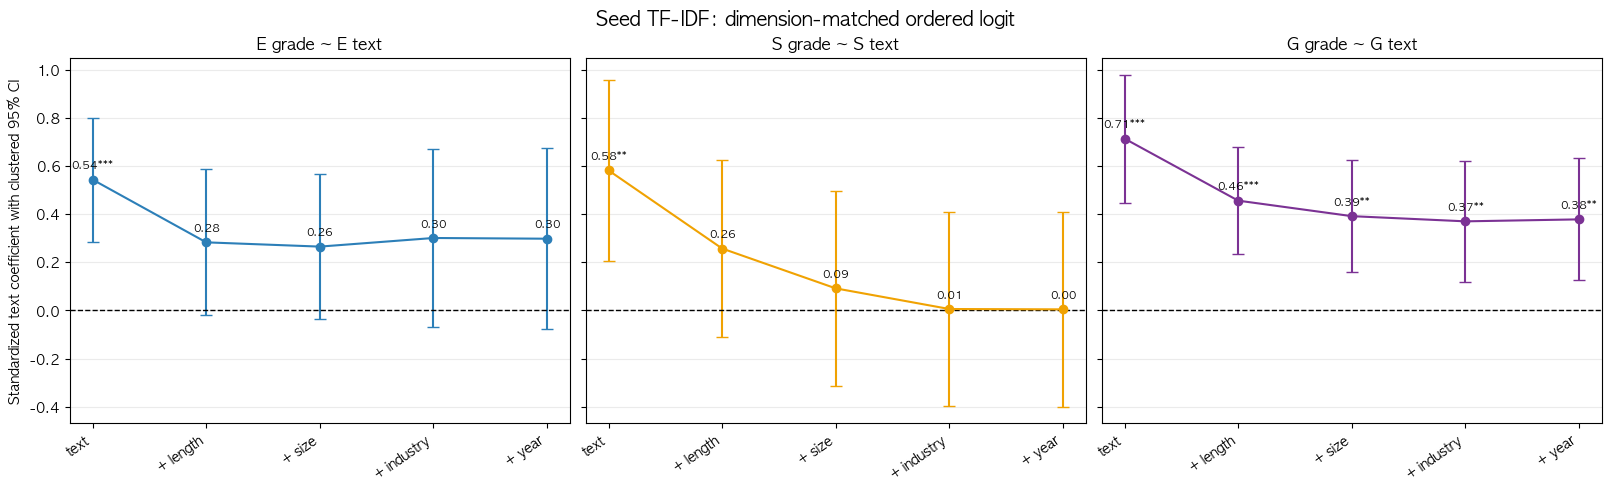

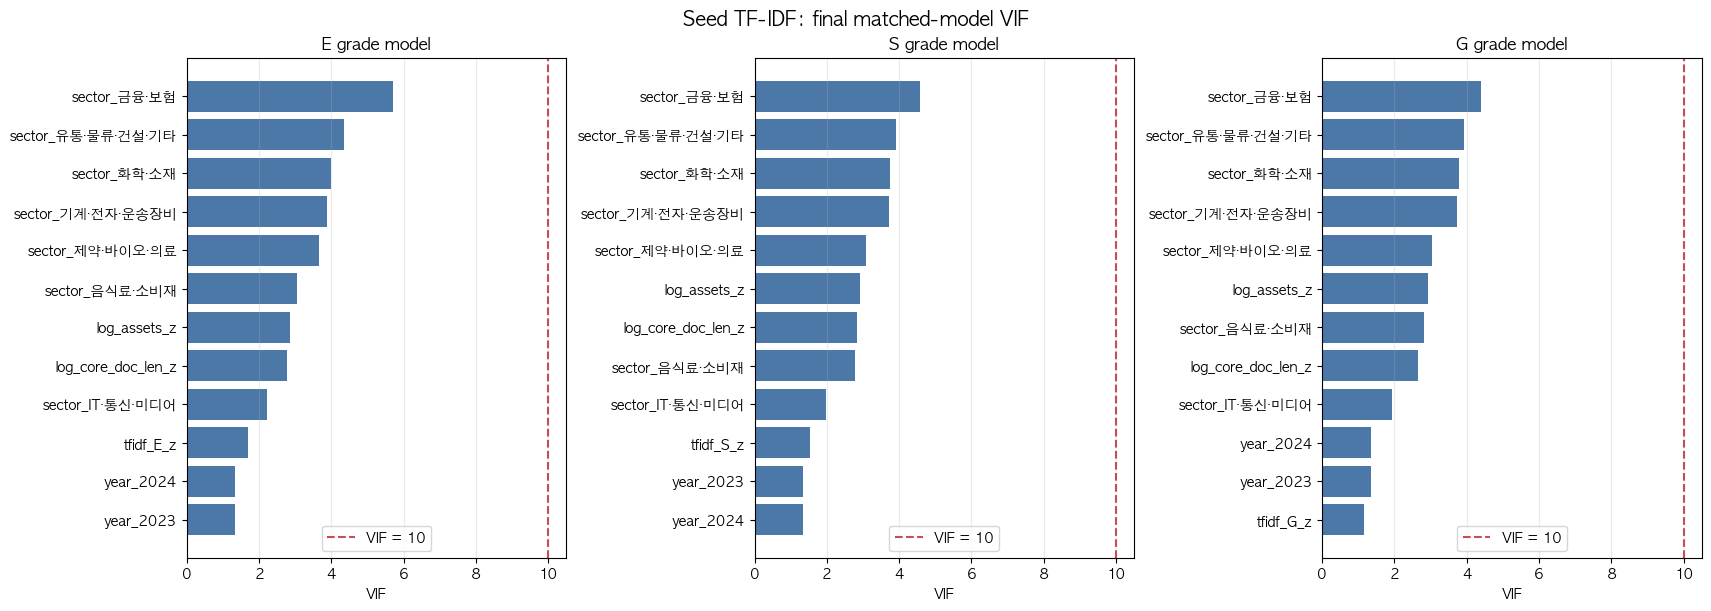


===== 통합 ESG 회귀: E + S + G 점수 계수 변화 =====


spec,term,coef,std_err_clustered,ci_low,ci_high,p_value,significance,aic
01_text_only,tfidf_E_z,0.288,0.136,0.023,0.554,0.0334,*,1196.1
01_text_only,tfidf_S_z,0.344,0.146,0.057,0.630,0.0187,*,1196.1
01_text_only,tfidf_G_z,0.668,0.124,0.425,0.910,6.86e-08,***,1196.1
02_add_length,tfidf_E_z,0.174,0.131,-0.083,0.430,0.184,,1077.8
02_add_length,tfidf_S_z,0.004,0.141,-0.272,0.279,0.978,,1077.8
02_add_length,tfidf_G_z,0.557,0.114,0.335,0.780,9.25e-07,***,1077.8
03_add_size,tfidf_E_z,0.191,0.131,-0.067,0.448,0.147,,1039.2
03_add_size,tfidf_S_z,-0.072,0.147,-0.361,0.217,0.626,,1039.2
03_add_size,tfidf_G_z,0.474,0.117,0.246,0.703,4.7e-05,***,1039.2
04_add_industry,tfidf_E_z,0.341,0.161,0.026,0.657,0.0341,*,1025.6



===== 통합 ESG 최종 사양(05_add_year) 전체 계수 =====


spec,term,term_type,coef,std_err_clustered,ci_low,ci_high,p_value,significance
05_add_year,tfidf_E_z,text_score,0.350,0.162,0.031,0.668,0.0312,*
05_add_year,tfidf_S_z,text_score,-0.063,0.185,-0.424,0.299,0.735,
05_add_year,tfidf_G_z,text_score,0.458,0.127,0.208,0.707,0.000323,***
05_add_year,log_core_doc_len_z,length,0.708,0.286,0.148,1.269,0.0133,*
05_add_year,log_assets_z,size,1.062,0.378,0.321,1.804,0.00499,**
05_add_year,sector_IT·통신·미디어,industry,2.614,0.704,1.235,3.994,0.000204,***
05_add_year,sector_금융·보험,industry,1.145,0.563,0.042,2.248,0.0418,*
05_add_year,sector_기계·전자·운송장비,industry,1.435,0.564,0.330,2.540,0.0109,*
05_add_year,sector_유통·물류·건설·기타,industry,1.700,0.602,0.520,2.880,0.00475,**
05_add_year,sector_음식료·소비재,industry,0.785,0.536,-0.266,1.835,0.143,


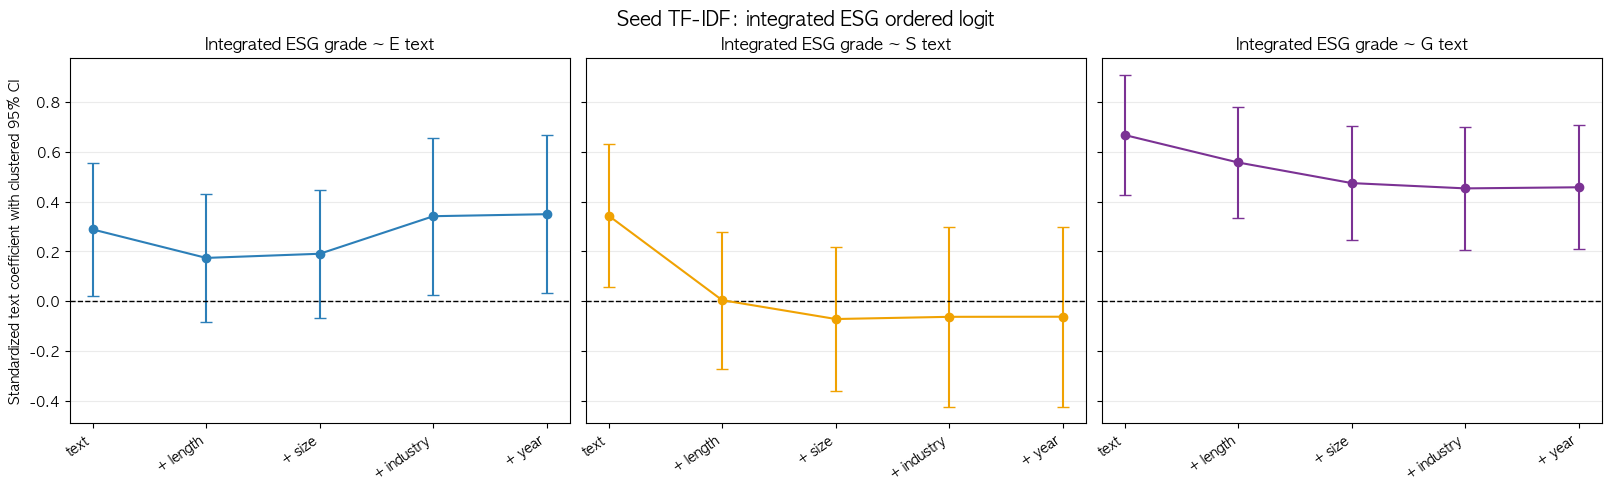

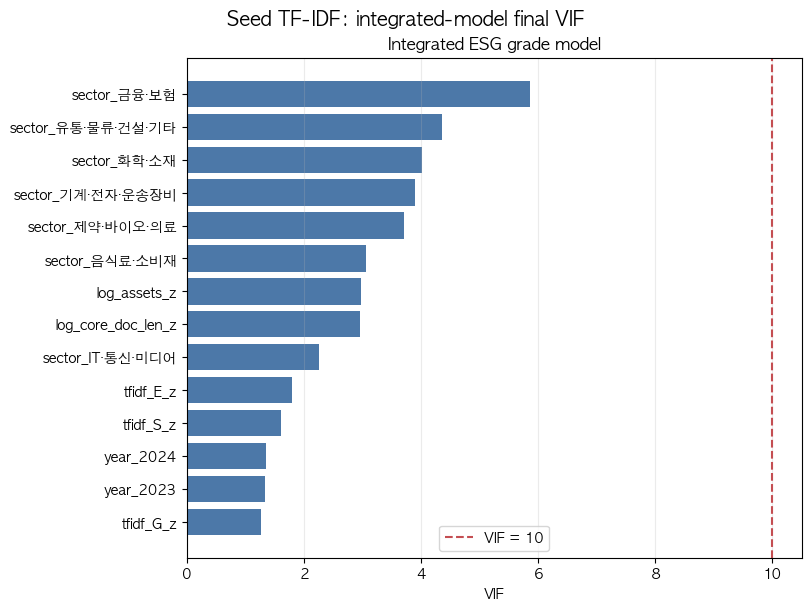

저장 완료: /Users/home1/esg-dart-project/data/processed/05b_tfidf_seed_matched_ordered_logit_summary.csv
저장 완료: /Users/home1/esg-dart-project/data/processed/05b_tfidf_seed_matched_ordered_logit_text_effects.csv
저장 완료: /Users/home1/esg-dart-project/data/processed/05b_tfidf_seed_matched_ordered_logit_vif.csv
저장 완료: /Users/home1/esg-dart-project/reports/figures/05b_tfidf_seed_matched_ordered_logit_text_effects.png
저장 완료: /Users/home1/esg-dart-project/reports/figures/05b_tfidf_seed_matched_ordered_logit_final_vif.png
저장 완료: /Users/home1/esg-dart-project/data/processed/05b_tfidf_seed_integrated_ordered_logit_summary.csv
저장 완료: /Users/home1/esg-dart-project/data/processed/05b_tfidf_seed_integrated_ordered_logit_vif.csv
저장 완료: /Users/home1/esg-dart-project/reports/figures/05b_tfidf_seed_integrated_ordered_logit_text_effects.png
저장 완료: /Users/home1/esg-dart-project/reports/figures/05b_tfidf_seed_integrated_ordered_logit_final_vif.png


In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

INDUSTRY_SECTOR_MAPPING_CSV = DATA_PROCESSED / 'industry_sector_mapping.csv'
SECTION_LENGTHS_CSV = DATA_PROCESSED / 'dart_section_lengths.csv'

MATCHED_OUTPUT_PREFIX = '05b_tfidf_seed'
OUTPUT_MATCHED_REGRESSION_SUMMARY = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_summary.csv'
OUTPUT_MATCHED_TEXT_EFFECTS = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_text_effects.csv'
OUTPUT_MATCHED_VIF = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_vif.csv'
OUTPUT_MATCHED_SUMMARY_DIR = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_summaries'
OUTPUT_MATCHED_EFFECT_PLOT = FIGURES_DIR / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_text_effects.png'
OUTPUT_MATCHED_VIF_PLOT = FIGURES_DIR / f'{MATCHED_OUTPUT_PREFIX}_matched_ordered_logit_final_vif.png'
OUTPUT_INTEGRATED_REGRESSION_SUMMARY = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_summary.csv'
OUTPUT_INTEGRATED_VIF = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_vif.csv'
OUTPUT_INTEGRATED_SUMMARY_DIR = DATA_PROCESSED / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_summaries'
OUTPUT_INTEGRATED_EFFECT_PLOT = FIGURES_DIR / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_text_effects.png'
OUTPUT_INTEGRATED_VIF_PLOT = FIGURES_DIR / f'{MATCHED_OUTPUT_PREFIX}_integrated_ordered_logit_final_vif.png'
OUTPUT_MATCHED_SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_INTEGRATED_SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

for path in [INDUSTRY_SECTOR_MAPPING_CSV, SECTION_LENGTHS_CSV]:
    assert path.exists(), f'통제변수 입력 파일 누락: {path}'


def normalize_stock_code(series: pd.Series) -> pd.Series:
    return series.astype('string').str.replace(r'\.0$', '', regex=True).str.zfill(6)


def zscore(series: pd.Series) -> pd.Series:
    std = series.std(ddof=0)
    assert std > 0, f'표준화할 변수의 표준편차가 0입니다: {series.name}'
    return (series - series.mean()) / std


def pvalue_stars_for_matched_regression(pval: float) -> str:
    if pd.isna(pval):
        return ''
    if pval < 0.001:
        return '***'
    if pval < 0.01:
        return '**'
    if pval < 0.05:
        return '*'
    return ''


industry_sector_mapping = pd.read_csv(
    INDUSTRY_SECTOR_MAPPING_CSV,
    dtype={'stock_code': 'string'},
)
section_lengths = pd.read_csv(
    SECTION_LENGTHS_CSV,
    dtype={'stock_code': 'string'},
)

required_industry_cols = {'stock_code', 'fiscal_year', 'sector', 'log_assets'}
required_length_cols = {'stock_code', 'fiscal_year', 'esg_year', 'len_II', 'len_IV', 'len_VI'}
assert required_industry_cols <= set(industry_sector_mapping.columns), (
    f'업종 매핑 필수 컬럼 누락: {required_industry_cols - set(industry_sector_mapping.columns)}'
)
assert required_length_cols <= set(section_lengths.columns), (
    f'문서 길이 필수 컬럼 누락: {required_length_cols - set(section_lengths.columns)}'
)

industry_sector_mapping['stock_code'] = normalize_stock_code(industry_sector_mapping['stock_code'])
industry_sector_mapping['fiscal_year'] = industry_sector_mapping['fiscal_year'].astype(int)
section_lengths['stock_code'] = normalize_stock_code(section_lengths['stock_code'])
section_lengths['fiscal_year'] = section_lengths['fiscal_year'].astype(int)
section_lengths['esg_year'] = section_lengths['esg_year'].astype(int)

assert industry_sector_mapping.duplicated(KEY_COLS).sum() == 0, '업종 매핑의 PK 중복이 있습니다.'
assert section_lengths.duplicated(STRICT_KEY_COLS).sum() == 0, '문서 길이의 strict PK 중복이 있습니다.'

matched_panel = merged.merge(
    industry_sector_mapping[['stock_code', 'fiscal_year', 'sector', 'log_assets']],
    on=KEY_COLS,
    how='left',
    validate='one_to_one',
    indicator='_industry_merge',
)
matched_panel = matched_panel.merge(
    section_lengths[STRICT_KEY_COLS + ['len_II', 'len_IV', 'len_VI']],
    on=STRICT_KEY_COLS,
    how='left',
    validate='one_to_one',
    indicator='_length_merge',
)

assert matched_panel['_industry_merge'].eq('both').all(), '업종·자산 통제 merge 누락이 있습니다.'
assert matched_panel['_length_merge'].eq('both').all(), '문서 길이 통제 merge 누락이 있습니다.'
matched_panel = matched_panel.drop(columns=['_industry_merge', '_length_merge'])

matched_panel['core_doc_len'] = matched_panel[['len_II', 'len_IV', 'len_VI']].sum(axis=1)
assert matched_panel['core_doc_len'].gt(0).all(), 'core 문서 길이가 0 이하인 행이 있습니다.'
matched_panel['log_core_doc_len'] = np.log1p(matched_panel['core_doc_len'])

required_panel_cols = ['sector', 'log_assets', 'log_core_doc_len'] + GRADE_NUM_COLS + REGRESSION_FEATURES
assert matched_panel[required_panel_cols].notna().all().all(), '최종 회귀 변수에 결측이 있습니다.'
assert len(matched_panel) == len(merged), '통제 merge 후 행 수가 달라졌습니다.'

MATCHED_TEXT_FEATURES = dict(zip(ESG_DIMS, REGRESSION_FEATURES))
MATCHED_GRADE_TARGETS = {
    'E': 'e_grade_num',
    'S': 's_grade_num',
    'G': 'g_grade_num',
}

for text_col in MATCHED_TEXT_FEATURES.values():
    matched_panel[f'{text_col}_z'] = zscore(matched_panel[text_col])
matched_panel['log_core_doc_len_z'] = zscore(matched_panel['log_core_doc_len'])
matched_panel['log_assets_z'] = zscore(matched_panel['log_assets'])

sector_dummies = pd.get_dummies(matched_panel['sector'], prefix='sector', drop_first=True, dtype=float)
year_dummies = pd.get_dummies(matched_panel['fiscal_year'], prefix='year', drop_first=True, dtype=float)
matched_panel = pd.concat([matched_panel, sector_dummies, year_dummies], axis=1)

included_sectors = {col.removeprefix('sector_') for col in sector_dummies.columns}
included_years = {int(col.removeprefix('year_')) for col in year_dummies.columns}
reference_sector = sorted(set(matched_panel['sector']) - included_sectors)
reference_year = sorted(set(matched_panel['fiscal_year']) - included_years)
assert len(reference_sector) == 1, f'업종 기준 범주 확정 실패: {reference_sector}'
assert len(reference_year) == 1, f'연도 기준 범주 확정 실패: {reference_year}'

CONTROL_BLOCKS = {
    '01_text_only': [],
    '02_add_length': ['log_core_doc_len_z'],
    '03_add_size': ['log_core_doc_len_z', 'log_assets_z'],
    '04_add_industry': ['log_core_doc_len_z', 'log_assets_z'] + list(sector_dummies.columns),
    '05_add_year': (
        ['log_core_doc_len_z', 'log_assets_z']
        + list(sector_dummies.columns)
        + list(year_dummies.columns)
    ),
}

print('최종 차원별 매칭 회귀 패널 shape:', matched_panel.shape)
print('기업 cluster 수:', matched_panel['stock_code'].nunique())
print('업종 더미 기준 범주:', reference_sector[0])
print('연도 더미 기준 범주:', reference_year[0])
print('통제변수 추가 순서:', list(CONTROL_BLOCKS))
print('\n차원별 회귀식:')
for dim in ESG_DIMS:
    print(f'{dim}_grade ~ {MATCHED_TEXT_FEATURES[dim]} + [길이 + 규모 + 업종 + 연도]')


def calculate_vif_for_matched_model(
    data: pd.DataFrame,
    predictors: list[str],
    dimension: str,
    spec_name: str,
) -> pd.DataFrame:
    vif_design = sm.add_constant(data[predictors].astype(float), has_constant='add')
    rows = []
    for idx, term in enumerate(vif_design.columns):
        if term == 'const':
            continue
        rows.append({
            'dimension': dimension,
            'spec': spec_name,
            'term': term,
            'vif': variance_inflation_factor(vif_design.to_numpy(), idx),
        })
    return pd.DataFrame(rows)


matched_regression_rows = []
matched_vif_frames = []
cluster_groups = matched_panel['stock_code']

for dimension in ESG_DIMS:
    text_feature_z = f'{MATCHED_TEXT_FEATURES[dimension]}_z'
    target_grade_num = MATCHED_GRADE_TARGETS[dimension]
    model_y = matched_panel[target_grade_num].astype(int)

    for spec_name, controls in CONTROL_BLOCKS.items():
        predictors = [text_feature_z] + controls
        model_X = matched_panel[predictors].astype(float)
        matched_vif_frames.append(
            calculate_vif_for_matched_model(matched_panel, predictors, dimension, spec_name)
        )

        ordered_model = OrderedModel(model_y, model_X, distr='logit')
        ordered_result = ordered_model.fit(
            method='bfgs',
            disp=False,
            cov_type='cluster',
            cov_kwds={'groups': cluster_groups},
        )
        assert ordered_result.cov_type == 'cluster', '기업별 cluster standard error 적용 실패'
        (OUTPUT_MATCHED_SUMMARY_DIR / f'{dimension}_{spec_name}_ordered_logit_summary.txt').write_text(
            ordered_result.summary().as_text(),
            encoding='utf-8',
        )

        for term in predictors:
            matched_regression_rows.append({
                'dimension': dimension,
                'target_grade_num': target_grade_num,
                'spec': spec_name,
                'term': term,
                'term_type': (
                    'text_score' if term == text_feature_z
                    else 'length' if term == 'log_core_doc_len_z'
                    else 'size' if term == 'log_assets_z'
                    else 'industry' if term.startswith('sector_')
                    else 'year'
                ),
                'coef': ordered_result.params[term],
                'std_err_clustered': ordered_result.bse[term],
                'p_value': ordered_result.pvalues[term],
                'aic': ordered_result.aic,
                'n_obs': int(ordered_result.nobs),
                'n_clusters': matched_panel['stock_code'].nunique(),
            })

matched_regression_summary = pd.DataFrame(matched_regression_rows)
matched_regression_summary['ci_low'] = (
    matched_regression_summary['coef'] - 1.96 * matched_regression_summary['std_err_clustered']
)
matched_regression_summary['ci_high'] = (
    matched_regression_summary['coef'] + 1.96 * matched_regression_summary['std_err_clustered']
)
matched_regression_summary['significance'] = matched_regression_summary['p_value'].map(
    pvalue_stars_for_matched_regression
)
matched_regression_summary.to_csv(
    OUTPUT_MATCHED_REGRESSION_SUMMARY,
    index=False,
    encoding='utf-8-sig',
)

matched_text_effects = matched_regression_summary.loc[
    matched_regression_summary['term_type'] == 'text_score'
].copy()
matched_text_effects.to_csv(OUTPUT_MATCHED_TEXT_EFFECTS, index=False, encoding='utf-8-sig')

matched_vif = pd.concat(matched_vif_frames, ignore_index=True)
matched_vif.to_csv(OUTPUT_MATCHED_VIF, index=False, encoding='utf-8-sig')

print('\n===== 같은 차원 텍스트 점수 계수 변화 =====')
display(
    matched_text_effects[
        [
            'dimension', 'spec', 'term', 'coef', 'std_err_clustered',
            'ci_low', 'ci_high', 'p_value', 'significance', 'aic', 'n_obs', 'n_clusters',
        ]
    ]
    .style
    .format({
        'coef': '{:.3f}', 'std_err_clustered': '{:.3f}',
        'ci_low': '{:.3f}', 'ci_high': '{:.3f}', 'p_value': '{:.3g}', 'aic': '{:.1f}',
    })
    .background_gradient(cmap='Blues', subset=['coef'])
    .hide(axis='index')
)

print('\n===== 최종 사양(05_add_year) 전체 계수 =====')
for dimension in ESG_DIMS:
    final_coef_view = matched_regression_summary.loc[
        (matched_regression_summary['dimension'] == dimension)
        & (matched_regression_summary['spec'] == '05_add_year'),
        [
            'dimension', 'spec', 'term', 'term_type', 'coef', 'std_err_clustered',
            'ci_low', 'ci_high', 'p_value', 'significance',
        ],
    ].reset_index(drop=True)
    print(f'\n[{dimension}_grade] 같은 차원 점수 + 길이 + 규모 + 업종 + 연도')
    display(
        final_coef_view.style
        .format({
            'coef': '{:.3f}', 'std_err_clustered': '{:.3f}',
            'ci_low': '{:.3f}', 'ci_high': '{:.3f}', 'p_value': '{:.3g}',
        })
        .background_gradient(cmap='Blues', subset=['coef'])
        .hide(axis='index')
    )

print('\n===== VIF 최대값: 차원별·사양별 =====')
matched_vif_max = matched_vif.groupby(['dimension', 'spec'], as_index=False)['vif'].max()
display(matched_vif_max.style.format({'vif': '{:.2f}'}).background_gradient(cmap='Reds', subset=['vif']))

# 같은 차원 점수의 통제변수 추가 전후 변화
SPEC_ORDER = list(CONTROL_BLOCKS)
DIMENSION_COLORS = {'E': '#2C7FB8', 'S': '#F0A202', 'G': '#7B3294'}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True, constrained_layout=True)
for ax, dimension in zip(axes, ESG_DIMS):
    plot_df = matched_text_effects.loc[
        matched_text_effects['dimension'] == dimension
    ].set_index('spec').reindex(SPEC_ORDER).reset_index()
    x_positions = np.arange(len(plot_df))
    ax.errorbar(
        x_positions,
        plot_df['coef'],
        yerr=[
            plot_df['coef'] - plot_df['ci_low'],
            plot_df['ci_high'] - plot_df['coef'],
        ],
        fmt='o-',
        capsize=4,
        color=DIMENSION_COLORS[dimension],
    )
    for x_pos, row in zip(x_positions, plot_df.itertuples(index=False)):
        ax.annotate(
            f'{row.coef:.2f}{row.significance}',
            (x_pos, row.coef),
            xytext=(0, 8),
            textcoords='offset points',
            ha='center',
            fontsize=8,
        )
    ax.axhline(0, color='black', ls='--', lw=1)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(['text', '+ length', '+ size', '+ industry', '+ year'], rotation=35, ha='right')
    ax.set_title(f'{dimension} grade ~ {dimension} text')
    ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('Standardized text coefficient with clustered 95% CI')
fig.suptitle('Seed TF-IDF: dimension-matched ordered logit', fontsize=14)
fig.savefig(OUTPUT_MATCHED_EFFECT_PLOT, dpi=200, bbox_inches='tight')
plt.show()

# 최종 사양 VIF
fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
for ax, dimension in zip(axes, ESG_DIMS):
    plot_vif = matched_vif.loc[
        (matched_vif['dimension'] == dimension) & (matched_vif['spec'] == '05_add_year')
    ].sort_values('vif', ascending=True)
    colors = ['#C44E52' if value >= 10 else '#4C78A8' for value in plot_vif['vif']]
    ax.barh(plot_vif['term'], plot_vif['vif'], color=colors)
    ax.axvline(10, color='#C44E52', ls='--', lw=1.5, label='VIF = 10')
    ax.set_title(f'{dimension} grade model')
    ax.set_xlabel('VIF')
    ax.legend()
    ax.grid(axis='x', alpha=0.25)
fig.suptitle('Seed TF-IDF: final matched-model VIF', fontsize=14)
fig.savefig(OUTPUT_MATCHED_VIF_PLOT, dpi=200, bbox_inches='tight')
plt.show()

# 통합 ESG 등급: E/S/G 점수를 함께 넣고 같은 통제변수 추가 경로를 비교한다.
integrated_regression_rows = []
integrated_vif_frames = []
integrated_text_features_z = [f'{MATCHED_TEXT_FEATURES[dim]}_z' for dim in ESG_DIMS]
integrated_y = matched_panel[INTEGRATED_GRADE_NUM_COL].astype(int)

for spec_name, controls in CONTROL_BLOCKS.items():
    predictors = integrated_text_features_z + controls
    model_X = matched_panel[predictors].astype(float)
    integrated_vif_frames.append(
        calculate_vif_for_matched_model(matched_panel, predictors, 'Integrated ESG', spec_name)
    )

    integrated_model = OrderedModel(integrated_y, model_X, distr='logit')
    integrated_result = integrated_model.fit(
        method='bfgs',
        disp=False,
        cov_type='cluster',
        cov_kwds={'groups': cluster_groups},
    )
    assert integrated_result.cov_type == 'cluster', '통합 회귀 cluster standard error 적용 실패'
    (OUTPUT_INTEGRATED_SUMMARY_DIR / f'{spec_name}_ordered_logit_summary.txt').write_text(
        integrated_result.summary().as_text(),
        encoding='utf-8',
    )

    for term in predictors:
        integrated_regression_rows.append({
            'spec': spec_name,
            'target_grade_num': INTEGRATED_GRADE_NUM_COL,
            'term': term,
            'term_type': (
                'text_score' if term in integrated_text_features_z
                else 'length' if term == 'log_core_doc_len_z'
                else 'size' if term == 'log_assets_z'
                else 'industry' if term.startswith('sector_')
                else 'year'
            ),
            'coef': integrated_result.params[term],
            'std_err_clustered': integrated_result.bse[term],
            'p_value': integrated_result.pvalues[term],
            'aic': integrated_result.aic,
            'n_obs': int(integrated_result.nobs),
            'n_clusters': matched_panel['stock_code'].nunique(),
        })

integrated_regression_summary = pd.DataFrame(integrated_regression_rows)
integrated_regression_summary['ci_low'] = (
    integrated_regression_summary['coef'] - 1.96 * integrated_regression_summary['std_err_clustered']
)
integrated_regression_summary['ci_high'] = (
    integrated_regression_summary['coef'] + 1.96 * integrated_regression_summary['std_err_clustered']
)
integrated_regression_summary['significance'] = integrated_regression_summary['p_value'].map(
    pvalue_stars_for_matched_regression
)
integrated_regression_summary.to_csv(
    OUTPUT_INTEGRATED_REGRESSION_SUMMARY,
    index=False,
    encoding='utf-8-sig',
)
integrated_vif = pd.concat(integrated_vif_frames, ignore_index=True)
integrated_vif.to_csv(OUTPUT_INTEGRATED_VIF, index=False, encoding='utf-8-sig')

print('\n===== 통합 ESG 회귀: E + S + G 점수 계수 변화 =====')
integrated_text_effects = integrated_regression_summary.loc[
    integrated_regression_summary['term_type'] == 'text_score'
].copy()
display(
    integrated_text_effects[
        ['spec', 'term', 'coef', 'std_err_clustered', 'ci_low', 'ci_high', 'p_value', 'significance', 'aic']
    ]
    .style
    .format({
        'coef': '{:.3f}', 'std_err_clustered': '{:.3f}',
        'ci_low': '{:.3f}', 'ci_high': '{:.3f}', 'p_value': '{:.3g}', 'aic': '{:.1f}',
    })
    .background_gradient(cmap='Blues', subset=['coef'])
    .hide(axis='index')
)

print('\n===== 통합 ESG 최종 사양(05_add_year) 전체 계수 =====')
display(
    integrated_regression_summary.loc[
        integrated_regression_summary['spec'] == '05_add_year',
        ['spec', 'term', 'term_type', 'coef', 'std_err_clustered', 'ci_low', 'ci_high', 'p_value', 'significance'],
    ]
    .style
    .format({
        'coef': '{:.3f}', 'std_err_clustered': '{:.3f}',
        'ci_low': '{:.3f}', 'ci_high': '{:.3f}', 'p_value': '{:.3g}',
    })
    .background_gradient(cmap='Blues', subset=['coef'])
    .hide(axis='index')
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True, constrained_layout=True)
for ax, dimension in zip(axes, ESG_DIMS):
    term = f'{MATCHED_TEXT_FEATURES[dimension]}_z'
    plot_df = integrated_text_effects.loc[
        integrated_text_effects['term'] == term
    ].set_index('spec').reindex(SPEC_ORDER).reset_index()
    x_positions = np.arange(len(plot_df))
    ax.errorbar(
        x_positions,
        plot_df['coef'],
        yerr=[plot_df['coef'] - plot_df['ci_low'], plot_df['ci_high'] - plot_df['coef']],
        fmt='o-',
        capsize=4,
        color=DIMENSION_COLORS[dimension],
    )
    ax.axhline(0, color='black', ls='--', lw=1)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(['text', '+ length', '+ size', '+ industry', '+ year'], rotation=35, ha='right')
    ax.set_title(f'Integrated ESG grade ~ {dimension} text')
    ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('Standardized text coefficient with clustered 95% CI')
fig.suptitle('Seed TF-IDF: integrated ESG ordered logit', fontsize=14)
fig.savefig(OUTPUT_INTEGRATED_EFFECT_PLOT, dpi=200, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
plot_integrated_vif = integrated_vif.loc[
    integrated_vif['spec'] == '05_add_year'
].sort_values('vif', ascending=True)
colors = ['#C44E52' if value >= 10 else '#4C78A8' for value in plot_integrated_vif['vif']]
ax.barh(plot_integrated_vif['term'], plot_integrated_vif['vif'], color=colors)
ax.axvline(10, color='#C44E52', ls='--', lw=1.5, label='VIF = 10')
ax.set_title('Integrated ESG grade model')
ax.set_xlabel('VIF')
ax.legend()
ax.grid(axis='x', alpha=0.25)
fig.suptitle('Seed TF-IDF: integrated-model final VIF', fontsize=14)
fig.savefig(OUTPUT_INTEGRATED_VIF_PLOT, dpi=200, bbox_inches='tight')
plt.show()

for path in [
    OUTPUT_MATCHED_REGRESSION_SUMMARY,
    OUTPUT_MATCHED_TEXT_EFFECTS,
    OUTPUT_MATCHED_VIF,
    OUTPUT_MATCHED_EFFECT_PLOT,
    OUTPUT_MATCHED_VIF_PLOT,
    OUTPUT_INTEGRATED_REGRESSION_SUMMARY,
    OUTPUT_INTEGRATED_VIF,
    OUTPUT_INTEGRATED_EFFECT_PLOT,
    OUTPUT_INTEGRATED_VIF_PLOT,
]:
    assert path.exists(), f'최종 차원별 매칭 회귀 산출물 저장 실패: {path}'
    print('저장 완료:', path)


### 해석 가이드

- 핵심은 각 차원의 같은 점수 계수다: `E grade ~ E text`, `S grade ~ S text`, `G grade ~ G text`.
- `01_text_only -> 05_add_year`로 이동할 때 계수가 얼마나 줄고 유의성이 어떻게 바뀌는지 본다.
- 길이를 추가한 직후 계수가 크게 줄면 문서 분량 효과가 섞였을 가능성이 있다.
- 규모·업종·연도를 추가한 뒤에도 계수가 유지되면 같은 영역의 disclosure signal 근거가 된다.
- VIF가 10 이상이면 다중공선성 검토가 필요하다.
- 통제 관찰 연구이므로 계수를 인과효과로 해석하지 않는다.


## 21. 부분 대각 ρ의 부트스트랩 CI · 순열검정 (G=0.17 이 0을 벗어나는가)

§12.2 부분 Spearman 대각(통제 후 그나마 생존하는 **G**)이 **0과 구분되는지**, **CI 가 얼마나 넓은지**를 재표집으로 직접 검증한다. 통제 스펙 2종을 함께 본다 — **(A) 분량+규모**(§12.2 와 동일, 업종 미통제)와 **(B) 분량+규모+업종**(매칭 ordered logit 과 동일, E 가 죽는 지점). 회귀가 기업 cluster SE 를 쓰므로 부트스트랩도 ① 행(381) ② 기업(127, 더 보수적) 두 가지로 보고하고, 순열검정으로 부분무관(H0) 귀무분포 대비 p 값을 낸다.

> **핵심 결과(실행값, 셀 하단 코멘트 참조)**: G 는 분량·규모만 통제하면 행/기업 부트 모두 0 제외(기업CI [+0.04, +0.30], 순열 p≈0.0007). 업종까지 통제하면 +0.149 로 내려가 기업 부트 하한이 **+0.001** 까지 붙는 경계 신호(순열 p≈0.0045). → *통제 후 G 만 약하게 생존하나 효과는 약하고 정밀도가 낮다.* (E 도 부분상관에선 두 스펙 모두 유의 — 회귀에서 E 소멸은 업종·연도·cluster SE 종합 효과.)

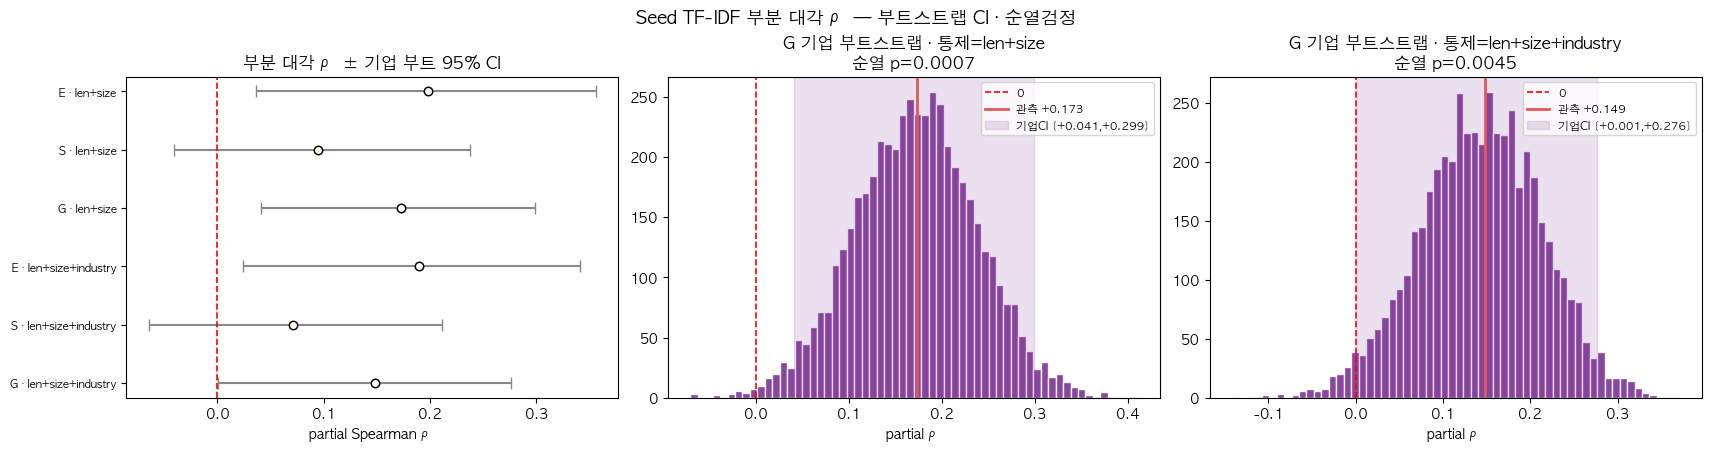

===== 부분 대각 ρ — 부트스트랩 95% CI · 순열 p =====
  [         len+size] E: obs +0.198 | 행CI [+0.089,+0.301] | 기업CI [+0.036,+0.356] | 순열p 0.0001 | 기업CI 0제외
  [         len+size] S: obs +0.095 | 행CI [-0.003,+0.192] | 기업CI [-0.041,+0.237] | 순열p 0.0646 | 기업CI 0포함
  [         len+size] G: obs +0.173 | 행CI [+0.074,+0.267] | 기업CI [+0.041,+0.299] | 순열p 0.0007 | 기업CI 0제외
  [len+size+industry] E: obs +0.189 | 행CI [+0.084,+0.284] | 기업CI [+0.024,+0.341] | 순열p 0.0003 | 기업CI 0제외
  [len+size+industry] S: obs +0.071 | 행CI [-0.030,+0.168] | 기업CI [-0.065,+0.211] | 순열p 0.1637 | 기업CI 0포함
  [len+size+industry] G: obs +0.149 | 행CI [+0.046,+0.247] | 기업CI [+0.001,+0.276] | 순열p 0.0045 | 기업CI 0제외
저장: /Users/home1/esg-dart-project/data/processed/05b_tfidf_seed_partial_spearman_ci.csv | /Users/home1/esg-dart-project/reports/figures/05b_tfidf_seed_partial_spearman_ci.png

[해석 가이드]
 • 행 부트=381행 복원, 기업 부트=127사 복원(같은 기업 3개연도 의존 반영 → 더 보수적·CI 넓음).
 • CI 가 0 '제외'면 통제 후에도 0 아님. 단 '유의=중요' 아님 — ρ≈0.15~0.20 은 약한 효과, CI 폭으로 정밀도 함께 

In [20]:
# ── 21. 부분 Spearman 대각(통제 후)의 부트스트랩 CI · 순열검정 ───────────────────────────
# 목적: §12.2 부분 3×3 대각(통제 후 그나마 생존하는 G)이 '0을 벗어나는지', 'CI 가 얼마나 넓은지'를
#   재표집으로 직접 확인. 통제 스펙 2종을 같이 본다:
#     (A) 분량+규모          → §12.2 와 동일(업종 미통제)
#     (B) 분량+규모+업종      → 매칭 ordered logit 과 동일(E 가 죽는 지점)
#   부트스트랩은 ① 행(381) ② 기업(127, 같은 기업 3개연도 의존 반영 → 보수적) 두 가지. 순열검정=부분무관 H0.
from scipy.stats import rankdata

N_BOOT, N_PERM = 5000, 10000
_rng = np.random.default_rng(20260602)

# 업종 더미 확보(cell 45 가 이미 sector_* 를 붙였으면 재사용, 아니면 생성)
sector_cols = [c for c in matched_panel.columns if c.startswith('sector_')]
if not sector_cols:
    _sd = pd.get_dummies(matched_panel['sector'], prefix='sector', drop_first=True, dtype=float)
    matched_panel = pd.concat([matched_panel, _sd], axis=1)
    sector_cols = list(_sd.columns)
CONTROL_SPECS = {'len+size': False, 'len+size+industry': True}   # value=업종 통제 여부
CONT_COLS = ['log_core_doc_len', 'log_assets']


def partial_spearman(x, y, cont, dummy=None):
    """rank 잔차화 부분 Spearman. 연속통제는 rank 화, 업종더미는 그대로 설계행렬에 투입."""
    rx, ry = rankdata(x), rankdata(y)
    cols = [np.ones(len(rx))] + [rankdata(cont[:, j]) for j in range(cont.shape[1])]
    if dummy is not None and dummy.shape[1] > 0:
        cols += [dummy[:, j] for j in range(dummy.shape[1])]
    A = np.column_stack(cols)
    ex = rx - A @ np.linalg.lstsq(A, rx, rcond=None)[0]
    ey = ry - A @ np.linalg.lstsq(A, ry, rcond=None)[0]
    return float(np.corrcoef(ex, ey)[0, 1]), ex, ey


cont_all = matched_panel[CONT_COLS].to_numpy(float)
dummy_all = matched_panel[sector_cols].to_numpy(float)
firms = matched_panel['stock_code'].to_numpy()
uniq_firms = np.unique(firms)
firm_rows = {f: np.where(firms == f)[0] for f in uniq_firms}

rows, store = [], {}     # store[(spec,dim)] = dict(보존: 분포·잔차) — G 시각화 재사용
for spec, use_ind in CONTROL_SPECS.items():
    D = dummy_all if use_ind else None
    for dim, tcol, gcol in zip(ESG_DIMS, TEXT_COLS, GRADE_NUM_COLS):
        x = matched_panel[tcol].to_numpy(float)
        y = matched_panel[gcol].to_numpy(float)
        n = len(x)
        obs, ex, ey = partial_spearman(x, y, cont_all, D)
        # ① 행 부트스트랩
        rb = np.empty(N_BOOT)
        for b in range(N_BOOT):
            idx = _rng.integers(0, n, n)
            rb[b] = partial_spearman(x[idx], y[idx], cont_all[idx], None if D is None else D[idx])[0]
        # ② 기업 부트스트랩
        cb = np.empty(N_BOOT)
        for b in range(N_BOOT):
            pick = _rng.choice(uniq_firms, len(uniq_firms), replace=True)
            idx = np.concatenate([firm_rows[f] for f in pick])
            cb[b] = partial_spearman(x[idx], y[idx], cont_all[idx], None if D is None else D[idx])[0]
        # ③ 순열검정
        perm = np.array([np.corrcoef(ex, _rng.permutation(ey))[0, 1] for _ in range(N_PERM)])
        p_perm = (np.sum(np.abs(perm) >= abs(obs)) + 1) / (N_PERM + 1)
        rci = np.percentile(rb, [2.5, 97.5]); cci = np.percentile(cb, [2.5, 97.5])
        rows.append(dict(spec=spec, dim=dim, obs=round(obs, 4),
                         row_lo=round(rci[0], 4), row_hi=round(rci[1], 4),
                         clu_lo=round(cci[0], 4), clu_hi=round(cci[1], 4),
                         perm_p=round(p_perm, 4),
                         row_excl0=bool(rci[0] > 0 or rci[1] < 0),
                         clu_excl0=bool(cci[0] > 0 or cci[1] < 0)))
        store[(spec, dim)] = dict(obs=obs, rb=rb, cb=cb, perm=perm, rci=rci, cci=cci, p=p_perm)

ci_table = pd.DataFrame(rows)
OUTPUT_PARTIAL_CI = DATA_PROCESSED / '05b_tfidf_seed_partial_spearman_ci.csv'
ci_table.to_csv(OUTPUT_PARTIAL_CI, index=False, encoding='utf-8-sig')

# ── 시각화 ① 전 차원×스펙 forest(obs ± 기업CI) ② G len+size 기업부트 ③ G +업종 기업부트 ──
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4), constrained_layout=True)
labels, xs, los, his, cols = [], [], [], [], []
palette = {'E': '#2C7FB8', 'S': '#F0A202', 'G': '#7B3294'}
for k, r in enumerate(rows):
    labels.append(f"{r['dim']} · {r['spec']}")
    xs.append(r['obs']); los.append(r['obs'] - r['clu_lo']); his.append(r['clu_hi'] - r['obs'])
    cols.append(palette[r['dim']])
ypos = np.arange(len(labels))[::-1]
ax[0].errorbar(xs, ypos, xerr=[los, his], fmt='o', capsize=4, ecolor='#888',
               mfc='white', mec='k', ls='none')
for yp, xv, c in zip(ypos, xs, cols):
    ax[0].plot(xv, yp, 'o', color=c)
ax[0].axvline(0, color='r', ls='--', lw=1.2)
ax[0].set_yticks(ypos); ax[0].set_yticklabels(labels, fontsize=8)
ax[0].set_title('부분 대각 ρ ± 기업 부트 95% CI'); ax[0].set_xlabel('partial Spearman ρ')
for a, spec in zip(ax[1:], ['len+size', 'len+size+industry']):
    g = store[(spec, 'G')]
    a.hist(g['cb'], bins=60, color='#7B3294', edgecolor='white', alpha=0.9)
    a.axvline(0, color='r', ls='--', lw=1.2, label='0')
    a.axvline(g['obs'], color='#E45756', lw=2, label=f"관측 {g['obs']:+.3f}")
    a.axvspan(g['cci'][0], g['cci'][1], color='#7B3294', alpha=0.15,
              label=f"기업CI [{g['cci'][0]:+.3f},{g['cci'][1]:+.3f}]")
    a.set_title(f"G 기업 부트스트랩 · 통제={spec}\n순열 p={g['p']:.4f}")
    a.set_xlabel('partial ρ'); a.legend(fontsize=8)
fig.suptitle('Seed TF-IDF 부분 대각 ρ — 부트스트랩 CI · 순열검정', fontsize=13)
PARTIAL_CI_PLOT = FIGURES_DIR / '05b_tfidf_seed_partial_spearman_ci.png'
fig.savefig(PARTIAL_CI_PLOT, dpi=200, bbox_inches='tight'); plt.show()

# ── 샘플: 결과 표 출력 ──
print('===== 부분 대각 ρ — 부트스트랩 95% CI · 순열 p =====')
for r in rows:
    flag = '기업CI 0제외' if r['clu_excl0'] else '기업CI 0포함'
    print(f"  [{r['spec']:>17}] {r['dim']}: obs {r['obs']:+.3f} | "
          f"행CI [{r['row_lo']:+.3f},{r['row_hi']:+.3f}] | 기업CI [{r['clu_lo']:+.3f},{r['clu_hi']:+.3f}] | "
          f"순열p {r['perm_p']:.4f} | {flag}")
print('저장:', OUTPUT_PARTIAL_CI, '|', PARTIAL_CI_PLOT)

# ── 해석 가이드 ──
print('\n[해석 가이드]')
print(" • 행 부트=381행 복원, 기업 부트=127사 복원(같은 기업 3개연도 의존 반영 → 더 보수적·CI 넓음).")
print(" • CI 가 0 '제외'면 통제 후에도 0 아님. 단 '유의=중요' 아님 — ρ≈0.15~0.20 은 약한 효과, CI 폭으로 정밀도 함께 보고.")
print(" • 순열 p = 부분무관(H0) 하에서 |관측ρ| 이상 확률. 작을수록 0 아님의 증거.")

# ══════════════════════════════════════════════════════════════════════════════════════════
# 〔실행 결과 코멘트 · 2026-06-02 · seed=20260602 · N_BOOT=5000 · N_PERM=10000 · 셀 결정적 재현〕
#   통제 = 분량(log_core_doc_len) + 규모(log_assets):
#     E: obs +0.198 | 행CI [+0.089,+0.301] | 기업CI [+0.036,+0.356] | 순열p 0.0001 | 0 제외
#     S: obs +0.095 | 행CI [-0.003,+0.192] | 기업CI [-0.041,+0.237] | 순열p 0.0646 | 0 포함(비유의)
#     G: obs +0.173 | 행CI [+0.074,+0.267] | 기업CI [+0.041,+0.299] | 순열p 0.0007 | 0 제외
#   통제 = 분량 + 규모 + 업종(sector 더미):
#     E: obs +0.189 | 행CI [+0.084,+0.284] | 기업CI [+0.024,+0.341] | 순열p 0.0003 | 0 제외
#     S: obs +0.071 | 행CI [-0.030,+0.168] | 기업CI [-0.065,+0.211] | 순열p 0.1637 | 0 포함(비유의)
#     G: obs +0.149 | 행CI [+0.046,+0.247] | 기업CI [+0.001,+0.276] | 순열p 0.0045 | 0 제외(하한 +0.001=경계)
# ▶ 결론: G(+0.17) 는 분량·규모만 통제하면 행/기업 부트 모두 0 제외(순열 p≈0.0007) → 통계적으로 0 과 구분된다.
#   다만 ① CI 가 넓고(기업 [.04,.30]) ② 업종까지 통제하면 +0.149 로 내려가 기업 부트 하한이 +0.001 까지 붙어
#   '겨우 0 제외'하는 경계 신호가 된다(순열 p 는 0.0045 로 여전히 유의). → "통제 후 G 만 약하게 생존"은 맞되
#   효과는 약하고 정밀도가 낮다(특히 업종 통제 시). 한편 E 도 부분상관에선 두 스펙 모두 0 제외로 유의 —
#   매칭 ordered logit 에서 E 가 죽은 건 업종·연도·기업 cluster SE 가 함께 들어간 종합 결과이지
#   '분량·규모 통제만'으로 죽는 게 아니다(보고서에서 회귀 결과와 구분해 서술). '유의=중요' 아님.
# ══════════════════════════════════════════════════════════════════════════════════════════
